# Gamer Behavior Clustering & Player Profiling

**Phân khúc người chơi game online theo lối chơi bằng Agglomerative Hierarchical Clustering kết hợp K-Means**

---

## Tóm tắt

| | |
|---|---|
| **Câu hỏi** | Người chơi chia thành những nhóm lối chơi nào, và nên kiếm tiền từ mỗi nhóm ra sao? |
| **Dữ liệu** | 40.034 người chơi, 13 cột (Kaggle *Predict Online Gaming Behavior*) |
| **Đặc trưng** | Giờ chơi/tuần, Level, Thành tựu |
| **Phương pháp** | Agglomerative (Ward) chọn k và tâm khởi tạo → K-Means trên toàn bộ dữ liệu |
| **Kết quả** | 4 phân khúc: Hardcore, Veteran Grinders, Achievement Hunters, Casual. Silhouette 0,276 · Davies-Bouldin 1,059 |

**Năm phát hiện chính**
1. `PlayTimeHours` không phản ánh mức gắn bó (r ≈ 0); **giờ chơi/tuần** mới là chỉ số đúng, và `EngagementLevel` gần như được suy ra trực tiếp từ nó.
2. Dữ liệu có **xu hướng phân cụm yếu** (Hopkins ≈ 0,58, gần mức ngẫu nhiên 0,5), nên Silhouette ở mức vừa phải là giới hạn của dữ liệu.
3. Hybrid **tốt hơn rõ** Agglomerative đơn thuần và **ngang** K-Means++, với chi phí một lần chạy.
4. Kiểm tra độ ổn định cho thấy **nhóm Hardcore là phân khúc vững nhất**, được tìm lại ở mọi lần chạy (trùng khớp ≈ 85%); ba nhóm còn lại là cách chia một vùng dữ liệu phân bố đều, nên ranh giới giữa chúng thay đổi theo mẫu.
5. Tỉ lệ mua hàng **không khác nhau** giữa các nhóm (kiểm định χ², p ≈ 0,36), và Gradient Boosting dùng mọi cột cũng chỉ đạt AUC ≈ 0,50: dataset không có nhóm High-Spender.

**Mô hình bổ sung:** GMM định lượng ranh giới mềm (≈ 20% người chơi giáp ranh; Hardcore chỉ 1%); cây quyết định 3 tầng xếp đúng phân khúc cho ≈ 91% người chơi bằng 8 quy tắc.

## Mục lục
0. Thiết lập · 1. Khám phá dữ liệu · 2. Tạo đặc trưng · 3. Dữ liệu có cấu trúc cụm không? · 4. Chuẩn hóa · 5. Agglomerative và chọn k · 6. Hybrid Agglomerative → K-Means · 7. Đánh giá · 8. Độ ổn định · 9. Hồ sơ phân khúc · 10. Chi tiêu · 11. Mô hình bổ sung (GMM, cây quyết định, Gradient Boosting) · 12. Chiến lược monetization · 13. Kết luận

## 0. Thiết lập môi trường và tải dữ liệu

- `SEED = 42` cố định mọi bước ngẫu nhiên để **kết quả tái lập được**.
- Chạy được trên máy (đọc `../data/`) hoặc Google Colab (tự tải dataset bằng `kagglehub`).
- Biểu đồ lưu vào `reports/figures/` (trên Colab là `figures/`).
- **Quy ước biểu đồ:** tiêu đề in đậm là *kết luận* của biểu đồ, dòng phụ bên dưới là *cách đọc*. Màu xanh đánh dấu thứ cần chú ý, màu xám là bối cảnh. Mỗi phân khúc giữ **một màu cố định** ở mọi biểu đồ; bộ màu đã được kiểm tra để người mù màu vẫn phân biệt được.

In [1]:
import os, glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, adjusted_rand_score

warnings.filterwarnings('ignore', category=FutureWarning)
SEED = 42

# Chart tokens: colour-blind-checked palette, recessive grid
INK, INK2, MUTED, GRID, GRAY, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
BLUE, RED, NEUTRAL = '#2a78d6', '#e34948', '#f0efec'
BLUE_RAMP = ['#86b6ef', '#2a78d6', '#104281']          # ordinal: low -> high
DIVERGING = LinearSegmentedColormap.from_list('div', [BLUE, NEUTRAL, RED])
SEG_ORDER = ['Hardcore', 'Veteran Grinders', 'Achievement Hunters', 'Casual']
SEG_COLORS = dict(zip(SEG_ORDER, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']))
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRAY, 'axes.labelcolor': INK2, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID,
    'grid.linewidth': 0.8, 'axes.axisbelow': True, 'axes.titlesize': 11, 'axes.titlecolor': INK,
    'axes.titlelocation': 'left', 'font.size': 10, 'legend.frameon': False,
})

def finish(fig, name, title, subtitle):
    # headline = the finding; subtitle = how to read the chart
    h = fig.get_figheight()
    fig.suptitle(title, x=0.01, y=1 - 0.12 / h, ha='left', va='top', fontsize=14, fontweight='bold', color=INK)
    fig.text(0.01, 1 - 0.5 / h, subtitle, ha='left', va='top', fontsize=10, color=INK2)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.62 / h))
    fig.savefig(f'{FIG_DIR}/{name}.png', dpi=150); plt.show()

def label_bars(ax, values, ys, fmt, pad=0.01):
    for y, v in zip(ys, values):
        ax.text(v + pad, y, fmt.format(v), va='center', color=INK, bbox=dict(fc=SURFACE, ec='none', pad=1))

DATA_DIR = '../data' if os.path.isdir('../data') else 'data'
FIG_DIR = '../reports/figures' if os.path.isdir('../reports') else 'figures'
os.makedirs(FIG_DIR, exist_ok=True)
CSV = os.path.join(DATA_DIR, 'online_gaming_behavior_dataset.csv')

if not os.path.exists(CSV):  # Colab: download from Kaggle
    import kagglehub
    path = kagglehub.dataset_download('rabieelkharoua/predict-online-gaming-behavior-dataset')
    CSV = glob.glob(os.path.join(path, '*.csv'))[0]

df = pd.read_csv(CSV)
assert len(df) == 40034 and df.isna().sum().sum() == 0, 'unexpected dataset version'
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40034 entries, 0 to 40033
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PlayerID                   40034 non-null  int64  
 1   Age                        40034 non-null  int64  
 2   Gender                     40034 non-null  object 
 3   Location                   40034 non-null  object 
 4   GameGenre                  40034 non-null  object 
 5   PlayTimeHours              40034 non-null  float64
 6   InGamePurchases            40034 non-null  int64  
 7   GameDifficulty             40034 non-null  object 
 8   SessionsPerWeek            40034 non-null  int64  
 9   AvgSessionDurationMinutes  40034 non-null  int64  
 10  PlayerLevel                40034 non-null  int64  
 11  AchievementsUnlocked       40034 non-null  int64  
 12  EngagementLevel            40034 non-null  object 
dtypes: float64(1), int64(7), object(5)
memory usag

,PlayerID,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
0,9000,43,Male,Other,Strategy,16.271119,0,Medium,6,108,79,25,Medium
1,9001,29,Female,USA,Strategy,5.525961,0,Medium,5,144,11,10,Medium
2,9002,22,Female,USA,Sports,8.223755,0,Easy,16,142,35,41,High
3,9003,35,Male,USA,Action,5.265351,1,Easy,9,85,57,47,Medium
4,9004,33,Male,Europe,Action,15.531945,0,Medium,2,131,95,37,Medium


**Mô tả các cột:**

| Cột | Ý nghĩa | Kiểu / miền giá trị |
|---|---|---|
| PlayerID | Mã người chơi | định danh (không dùng) |
| Age, Gender, Location | Nhân khẩu học | 15–49 / Male, Female / USA, Europe, Asia, Other |
| GameGenre | Thể loại game chơi chính | 5 loại |
| PlayTimeHours | Giờ chơi trung bình | 0–24 |
| InGamePurchases | Có mua hàng trong game | 0 / 1 |
| GameDifficulty | Độ khó chọn chơi | Easy / Medium / Hard |
| SessionsPerWeek | Số phiên chơi mỗi tuần | 0–19 |
| AvgSessionDurationMinutes | Thời lượng trung bình mỗi phiên (phút) | 10–179 |
| PlayerLevel | Cấp độ nhân vật | 1–99 |
| AchievementsUnlocked | Số thành tựu đã mở | 0–49 |
| EngagementLevel | Mức độ gắn bó (nhãn có sẵn) | Low / Medium / High |

Dữ liệu **không có giá trị thiếu**, nên không cần bước xử lý missing values.

## 1. Khám phá dữ liệu (EDA)

Ba câu hỏi cho phần này:
1. Dữ liệu có sạch không (trùng lặp, bất thường)?
2. Mỗi biến phân bố ra sao?
3. Biến nào **thực sự phản ánh hành vi chơi**? Dùng `EngagementLevel` làm thước đo đối chiếu.

In [2]:
print('Duplicates:', df.duplicated().sum())
display(df.describe().T.round(2))
for c in ['Gender', 'Location', 'GameGenre', 'GameDifficulty', 'EngagementLevel']:
    print(f'{c:16}', df[c].value_counts(normalize=True).round(3).to_dict())

Duplicates: 0


,count,mean,std,min,25%,50%,75%,max
PlayerID,40034.0,29016.50,11556.96,9000.0,19008.25,29016.50,39024.75,49033.0
Age,40034.0,31.99,10.04,15.0,23.00,32.00,41.00,49.0
PlayTimeHours,40034.0,12.02,6.91,0.0,6.07,12.01,17.96,24.0
InGamePurchases,40034.0,0.20,0.40,0.0,0.00,0.00,0.00,1.0
SessionsPerWeek,40034.0,9.47,5.76,0.0,4.00,9.00,14.00,19.0
AvgSessionDurationMinutes,40034.0,94.79,49.01,10.0,52.00,95.00,137.00,179.0
PlayerLevel,40034.0,49.66,28.59,1.0,25.00,49.00,74.00,99.0
AchievementsUnlocked,40034.0,24.53,14.43,0.0,12.00,25.00,37.00,49.0


Gender           {'Male': 0.598, 'Female': 0.402}
Location         {'USA': 0.4, 'Europe': 0.3, 'Asia': 0.202, 'Other': 0.098}
GameGenre        {'Sports': 0.201, 'Action': 0.201, 'Strategy': 0.2, 'Simulation': 0.199, 'RPG': 0.199}
GameDifficulty   {'Easy': 0.5, 'Medium': 0.3, 'Hard': 0.2}
EngagementLevel  {'Medium': 0.484, 'High': 0.258, 'Low': 0.258}


**Nhận xét:**
- Không có dòng trùng lặp.
- Các biến phân loại chia **đều gần như tuyệt đối**: 5 thể loại game mỗi loại ≈ 20%, độ khó đúng 50/30/20, engagement 26/48/26. Dữ liệu thật hiếm khi tròn như vậy, nên đây nhiều khả năng là **dữ liệu tổng hợp (synthetic)**. Mục 3 sẽ kiểm chứng nhận định này bằng một chỉ số định lượng.

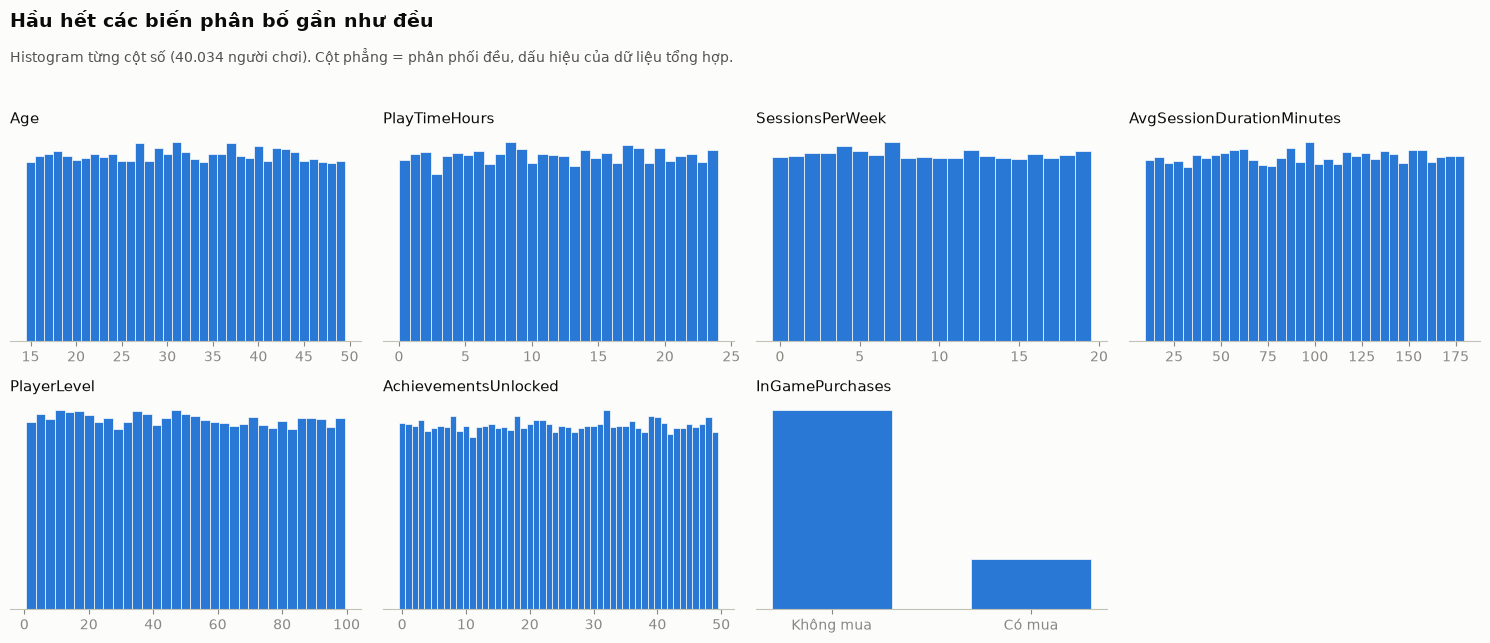

In [3]:
num = ['Age', 'PlayTimeHours', 'SessionsPerWeek', 'AvgSessionDurationMinutes',
       'PlayerLevel', 'AchievementsUnlocked', 'InGamePurchases']
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for a, c in zip(axes.flat, num):
    binary = df[c].nunique() == 2
    integer = (df[c] % 1 == 0).all()
    n = int(df[c].max() - df[c].min() + 1)
    step = next(d for d in range(int(np.ceil(n / 50)), n + 1) if n % d == 0)  # equal integer values per bin
    bins = np.arange(df[c].min() - 0.5, df[c].max() + step, step) if integer else 30
    a.hist(df[c], bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=0.5, rwidth=0.6 if binary else 1)
    if binary: a.set_xticks([0, 1], ['Không mua', 'Có mua'])
    a.set_title(c); a.set_yticks([]); a.grid(False); a.spines['left'].set_visible(False)
axes.flat[-1].axis('off')
finish(fig, '01_distributions', 'Hầu hết các biến phân bố gần như đều',
       'Histogram từng cột số (40.034 người chơi). Cột phẳng = phân phối đều, dấu hiệu của dữ liệu tổng hợp.')

**Đọc biểu đồ:** hầu hết histogram **phẳng**: số người level 10 xấp xỉ số người level 90, số người chơi 2 giờ xấp xỉ số người chơi 20 giờ. Dữ liệu game thật thường lệch phải (nhiều người chơi ít, một nhóm nhỏ chơi rất nhiều). Không có ngoại lai, nên `StandardScaler` là đủ.

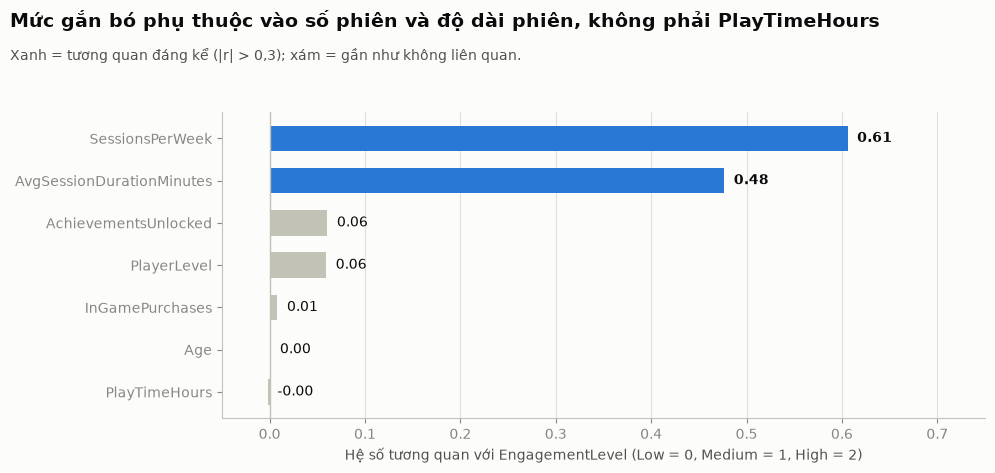

PlayTimeHours               -0.002
Age                          0.001
InGamePurchases              0.008
PlayerLevel                  0.059
AchievementsUnlocked         0.061
AvgSessionDurationMinutes    0.477
SessionsPerWeek              0.606
dtype: float64

In [4]:
eng_code = df['EngagementLevel'].map({'Low': 0, 'Medium': 1, 'High': 2})
corr = df[num].corrwith(eng_code).sort_values()
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(corr.index, corr, color=np.where(corr.abs() > 0.3, BLUE, GRAY), height=0.6)
for y, v in enumerate(corr):
    ax.text(v + 0.01, y, f'{v:.2f}', va='center', color=INK, fontweight='bold' if abs(v) > 0.3 else 'normal')
ax.axvline(0, color=GRAY, lw=1); ax.set_xlim(-0.05, 0.75); ax.grid(axis='y', visible=False)
ax.set_xlabel('Hệ số tương quan với EngagementLevel (Low = 0, Medium = 1, High = 2)')
finish(fig, '02_engagement_corr', 'Mức gắn bó phụ thuộc vào số phiên và độ dài phiên, không phải PlayTimeHours',
       'Xanh = tương quan đáng kể (|r| > 0,3); xám = gần như không liên quan.')
corr.round(3)

**Phát hiện quan trọng nhất của EDA:**
- `PlayTimeHours` **không tương quan** với mức gắn bó (r ≈ 0,00). Dùng nó làm chỉ số "playtime" sẽ đưa nhiễu vào phân cụm.
- `SessionsPerWeek` (r ≈ 0,61) và `AvgSessionDurationMinutes` (r ≈ 0,48) tương quan mạnh. Hai biến này nhân lại là **tổng giờ chơi mỗi tuần**.
- `PlayerLevel`, `AchievementsUnlocked` gần như độc lập với engagement: chúng mang **thông tin khác** (tiến trình, sưu tập), có ích cho phân cụm.

## 2. Tạo đặc trưng lối chơi (Feature engineering)

| Đề bài | Đặc trưng dùng | Lý do |
|---|---|---|
| Playtime | `WeeklyPlayHours` = SessionsPerWeek × AvgSessionDurationMinutes / 60 | Tổng thời gian chơi thực tế mỗi tuần |
| Skill score | `PlayerLevel` | Level cao = đã vượt nhiều thử thách (proxy) |
| Item collection rate | `AchievementsUnlocked` | Thành tựu là thứ người chơi "sưu tập" (proxy) |
| Win/loss ratio | không có | Dataset không ghi nhận thắng/thua → **hạn chế** |

**Không đưa vào phân cụm:**
- `InGamePurchases` (0/1): biến nhị phân sau chuẩn hóa tạo khoảng cách rất lớn giữa hai giá trị nên **chi phối** thuật toán. Dùng để mô tả hồ sơ ở mục 10.
- Biến nhân khẩu học: đề bài yêu cầu phân khúc theo **hành vi**; các biến này dùng để kiểm tra sau khi phân cụm.

Mục 3 sẽ so sánh bằng số liệu bộ đặc trưng này với các phương án khác.

corr(WeeklyPlayHours, Engagement) = 0.773


,count,mean,std,min,25%,50%,75%,max
WeeklyPlayHours,40034.0,14.96,12.85,0.0,4.47,11.4,22.73,56.68
PlayerLevel,40034.0,49.66,28.59,1.0,25.00,49.0,74.00,99.00
AchievementsUnlocked,40034.0,24.53,14.43,0.0,12.00,25.0,37.00,49.00


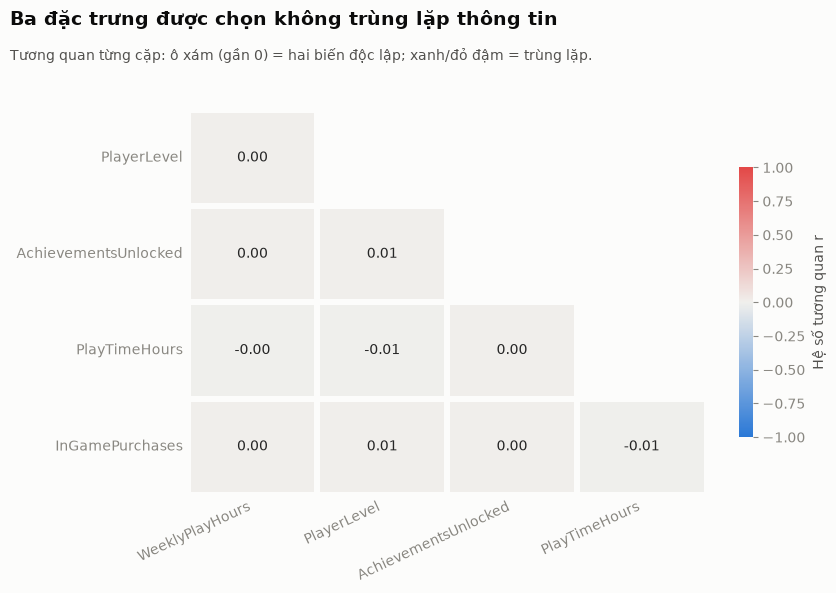

In [5]:
df['WeeklyPlayHours'] = df['SessionsPerWeek'] * df['AvgSessionDurationMinutes'] / 60
FEATURES = ['WeeklyPlayHours', 'PlayerLevel', 'AchievementsUnlocked']
print('corr(WeeklyPlayHours, Engagement) =', round(df['WeeklyPlayHours'].corr(eng_code), 3))
display(df[FEATURES].describe().T.round(2))

cm = df[FEATURES + ['PlayTimeHours', 'InGamePurchases']].corr().iloc[1:, :-1]
fig, ax = plt.subplots(figsize=(8.5, 6))
sns.heatmap(cm, mask=np.triu(np.ones_like(cm, dtype=bool), k=1), annot=True, fmt='.2f', cmap=DIVERGING,
            vmin=-1, vmax=1, linewidths=3, linecolor=SURFACE, cbar_kws={'shrink': 0.7, 'label': 'Hệ số tương quan r'}, ax=ax)
ax.grid(False); ax.tick_params(length=0); ax.tick_params(axis='x', rotation=25)
plt.setp(ax.get_xticklabels(), ha='right')
finish(fig, '03_feature_corr', 'Ba đặc trưng được chọn không trùng lặp thông tin',
       'Tương quan từng cặp: ô xám (gần 0) = hai biến độc lập; xanh/đỏ đậm = trùng lặp.')

**Kết quả:** `WeeklyPlayHours` có tương quan **0,77** với engagement, cao hơn mọi biến gốc. Ba đặc trưng **độc lập với nhau** (r ≈ 0), nên mỗi đặc trưng đóng góp một chiều thông tin riêng.

### 2.1 Nhãn EngagementLevel được tạo ra như thế nào?
Tương quan 0,77 cao bất thường, nên kiểm tra kỹ hơn: chia người chơi theo khoảng giờ chơi/tuần và xem tỉ lệ Low/Medium/High trong từng khoảng.

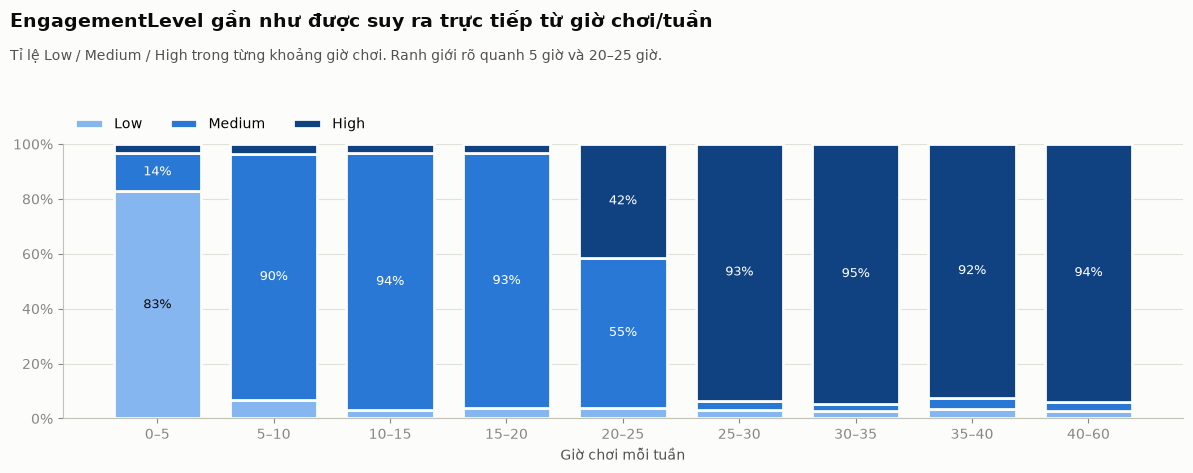

EngagementLevel,Low,Medium,High
WeeklyPlayHours,,,
"(-0.001, 5.0]",0.83,0.14,0.03
"(5.0, 10.0]",0.07,0.90,0.04
"(10.0, 15.0]",0.03,0.94,0.03
"(15.0, 20.0]",0.04,0.93,0.03
"(20.0, 25.0]",0.04,0.55,0.42
"(25.0, 30.0]",0.03,0.03,0.93
"(30.0, 35.0]",0.03,0.03,0.95
"(35.0, 40.0]",0.03,0.04,0.92
"(40.0, 60.0]",0.03,0.03,0.94


In [6]:
bands = pd.cut(df['WeeklyPlayHours'], [0, 5, 10, 15, 20, 25, 30, 35, 40, 60], include_lowest=True)
mix = pd.crosstab(bands, df['EngagementLevel'], normalize='index')[['Low', 'Medium', 'High']]
labels = [f'{int(i.left)}–{int(i.right)}' for i in mix.index]
fig, ax = plt.subplots(figsize=(12, 4.8))
bottom = np.zeros(len(mix))
for lvl, col in zip(['Low', 'Medium', 'High'], BLUE_RAMP):
    ax.bar(labels, mix[lvl], bottom=bottom, color=col, edgecolor=SURFACE, linewidth=2, width=0.75, label=lvl)
    for x, (b, v) in enumerate(zip(bottom, mix[lvl])):
        if v > 0.12: ax.text(x, b + v / 2, f'{v:.0%}', ha='center', va='center', color=INK if col == BLUE_RAMP[0] else 'white', fontsize=9)
    bottom += mix[lvl].values
ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_ylim(0, 1); ax.grid(axis='x', visible=False)
ax.set_xlabel('Giờ chơi mỗi tuần'); ax.legend(ncol=3, loc='lower left', bbox_to_anchor=(0, 1.0))
finish(fig, '04_engagement_rule', 'EngagementLevel gần như được suy ra trực tiếp từ giờ chơi/tuần',
       'Tỉ lệ Low / Medium / High trong từng khoảng giờ chơi. Ranh giới rõ quanh 5 giờ và 20–25 giờ.')
mix.round(2)

**Phát hiện:** nhãn engagement gần như là một **quy tắc theo ngưỡng**: dưới 5 giờ/tuần ≈ 80% Low; 5–20 giờ ≈ 90% Medium; trên 25 giờ ≈ 93% High; chỉ khoảng 20–25 giờ là vùng chuyển tiếp. Phần còn lại (~3–7%) giống như nhiễu được thêm vào.

**Hệ quả:**
- Xác nhận `WeeklyPlayHours` đúng là thước đo gắn bó mà bộ dữ liệu "ngầm" sử dụng.
- Nhãn `EngagementLevel` **không mang thêm thông tin** ngoài giờ chơi, nên không cần đưa vào phân cụm. Nó sẽ được dùng để **kiểm chứng** nhóm Hardcore ở mục 9.

## 3. Dữ liệu có cấu trúc cụm không?

Trước khi phân cụm, cần hỏi: dữ liệu có **xu hướng tạo cụm** không? Thuật toán phân cụm luôn trả về k cụm, kể cả trên dữ liệu ngẫu nhiên hoàn toàn.

### 3.1 Hopkins statistic
So sánh khoảng cách từ $m$ điểm **ngẫu nhiên đều** tới dữ liệu ($u_i$) với khoảng cách từ $m$ điểm **thật** tới láng giềng gần nhất của chúng ($w_i$):
$$H = \frac{\sum u_i}{\sum u_i + \sum w_i}$$
- $H \approx 0{,}5$: dữ liệu phân bố như ngẫu nhiên, không có cụm.
- $H \to 1$: dữ liệu tụ thành cụm rõ (điểm thật gần nhau hơn hẳn điểm ngẫu nhiên).
- Ngưỡng thường dùng: $H > 0{,}75$ là có xu hướng cụm đáng kể.

Để có mốc so sánh, tính thêm $H$ cho hai bộ dữ liệu giả cùng kích thước: **phân bố đều** (không có cụm) và **4 cụm Gauss tách biệt** (cụm rõ).

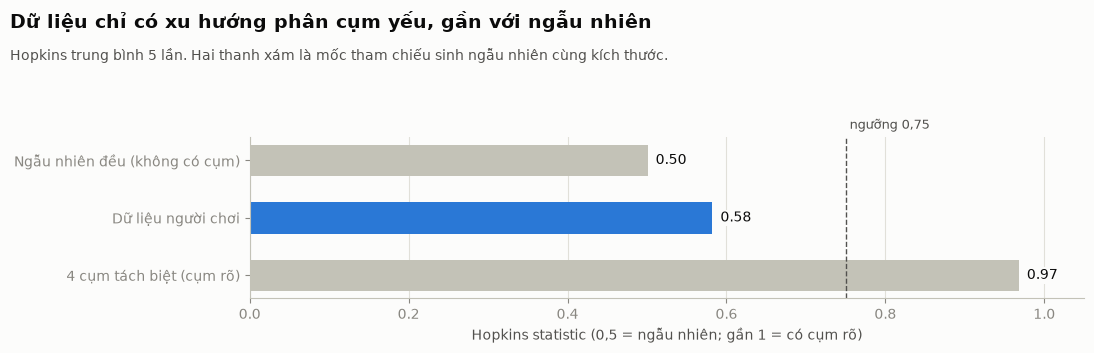

Ngẫu nhiên đều (không có cụm)    0.501
Dữ liệu người chơi               0.582
4 cụm tách biệt (cụm rõ)         0.968
dtype: float64

In [7]:
X = StandardScaler().fit_transform(df[FEATURES])

def hopkins(data, m=1000, seed=0):
    r = np.random.default_rng(seed)
    nn = NearestNeighbors(n_neighbors=2).fit(data)
    w = nn.kneighbors(data[r.choice(len(data), m, replace=False)])[0][:, 1]       # real point -> nearest other real point
    u = nn.kneighbors(r.uniform(data.min(0), data.max(0), (m, data.shape[1])), 1)[0][:, 0]  # random point -> nearest real point
    return u.sum() / (u.sum() + w.sum())

g = np.random.default_rng(SEED)
uniform_ref = g.uniform(size=X.shape)
blobs_ref = np.vstack([g.normal(c, 0.3, (len(X) // 4, 3)) for c in [(0, 0, 0), (3, 0, 0), (0, 3, 0), (0, 0, 3)]])
H = pd.Series({name: np.mean([hopkins(d, seed=s) for s in range(5)])
               for name, d in [('Ngẫu nhiên đều (không có cụm)', uniform_ref),
                               ('Dữ liệu người chơi', X),
                               ('4 cụm tách biệt (cụm rõ)', blobs_ref)]})
fig, ax = plt.subplots(figsize=(11, 3.6))
y = np.arange(len(H))[::-1]
ax.barh(y, H, color=[GRAY, BLUE, GRAY], height=0.55)
label_bars(ax, H, y, '{:.2f}')
ax.axvline(0.75, color=INK2, ls='--', lw=1); ax.text(0.755, len(H) - 0.45, 'ngưỡng 0,75', color=INK2, fontsize=9)
ax.set_yticks(y, H.index); ax.set_xlim(0, 1.05); ax.grid(axis='y', visible=False)
ax.set_xlabel('Hopkins statistic (0,5 = ngẫu nhiên; gần 1 = có cụm rõ)')
finish(fig, '05_hopkins', 'Dữ liệu chỉ có xu hướng phân cụm yếu, gần với ngẫu nhiên',
       'Hopkins trung bình 5 lần. Hai thanh xám là mốc tham chiếu sinh ngẫu nhiên cùng kích thước.')
H.round(3)

**Kết luận:** $H$ của dữ liệu thật ≈ **0,58**, gần mốc ngẫu nhiên (0,50) hơn nhiều so với mốc có cụm rõ (≈ 0,97), và dưới ngưỡng 0,75. Đây là **bằng chứng định lượng** cho nhận định ở EDA: dữ liệu gần như phân bố đều, các cụm (nếu có) sẽ chồng lấn. Vẫn có một chút cấu trúc (0,58 > 0,50), mục 8 sẽ chỉ ra cấu trúc đó nằm ở đâu.

**Ý nghĩa cho đề tài:** phân cụm vẫn hữu ích như một **cách chia có ý nghĩa kinh doanh** (segmentation), nhưng không nên kỳ vọng Silhouette cao, và cần kiểm tra cụm nào ổn định.

### 3.2 Bộ đặc trưng nào cho cụm tốt nhất? (Ablation)
So sánh bốn phương án đầu vào, cùng phương pháp Hybrid với k = 4 (định nghĩa ở mục 6):
- **5 biến gốc**: PlayTimeHours, SessionsPerWeek, AvgSessionDurationMinutes, PlayerLevel, AchievementsUnlocked.
- **PlayTimeHours thay giờ/tuần**: dùng biến giờ chơi gốc.
- **Đã chọn + InGamePurchases**: thêm biến mua hàng.
- **Đã chọn**: WeeklyPlayHours, PlayerLevel, AchievementsUnlocked.

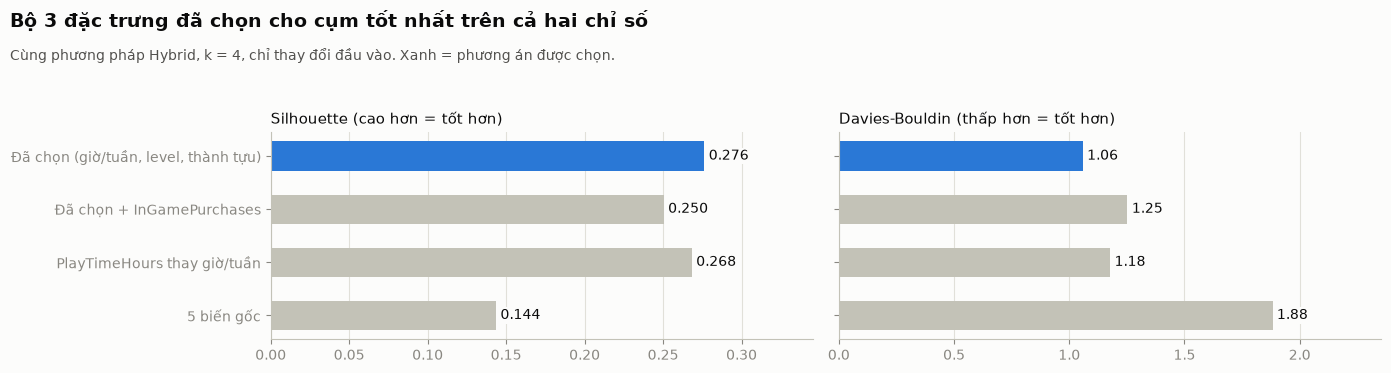

,n_features,silhouette,davies_bouldin
feature_set,,,
5 biến gốc,5,0.144,1.882
PlayTimeHours thay giờ/tuần,3,0.268,1.178
Đã chọn + InGamePurchases,4,0.250,1.253
"Đã chọn (giờ/tuần, level, thành tựu)",3,0.276,1.059


In [8]:
rng = np.random.default_rng(SEED)
idx_h = rng.choice(len(X), 5000, replace=False)    # hierarchical needs O(n^2) memory
idx_s = rng.choice(len(X), 10000, replace=False)   # silhouette is O(n^2)

def hybrid(data, k, idx):
    h = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(data[idx])
    init = np.array([data[idx][h == i].mean(axis=0) for i in range(k)])
    return KMeans(n_clusters=k, init=init, n_init=1, random_state=SEED).fit(data)

options = {
    '5 biến gốc': ['PlayTimeHours', 'SessionsPerWeek', 'AvgSessionDurationMinutes', 'PlayerLevel', 'AchievementsUnlocked'],
    'PlayTimeHours thay giờ/tuần': ['PlayTimeHours', 'PlayerLevel', 'AchievementsUnlocked'],
    'Đã chọn + InGamePurchases': FEATURES + ['InGamePurchases'],
    'Đã chọn (giờ/tuần, level, thành tựu)': FEATURES,
}
rows = []
for name, cols in options.items():
    Z = StandardScaler().fit_transform(df[cols]); lab = hybrid(Z, 4, idx_h).labels_
    rows.append({'feature_set': name, 'n_features': len(cols),
                 'silhouette': silhouette_score(Z[idx_s], lab[idx_s]), 'davies_bouldin': davies_bouldin_score(Z, lab)})
ablation = pd.DataFrame(rows).set_index('feature_set')

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
y = np.arange(len(ablation))
chosen = ablation.index == 'Đã chọn (giờ/tuần, level, thành tựu)'
for a, col, title, fmt in [(axes[0], 'silhouette', 'Silhouette (cao hơn = tốt hơn)', '{:.3f}'),
                           (axes[1], 'davies_bouldin', 'Davies-Bouldin (thấp hơn = tốt hơn)', '{:.2f}')]:
    a.barh(y, ablation[col], color=np.where(chosen, BLUE, GRAY), height=0.55)
    label_bars(a, ablation[col], y, fmt, pad=ablation[col].max() * 0.01)
    a.set_title(title); a.set_xlim(0, ablation[col].max() * 1.25); a.grid(axis='y', visible=False)
axes[0].set_yticks(y, ablation.index)
finish(fig, '06_feature_ablation', 'Bộ 3 đặc trưng đã chọn cho cụm tốt nhất trên cả hai chỉ số',
       'Cùng phương pháp Hybrid, k = 4, chỉ thay đổi đầu vào. Xanh = phương án được chọn.')
ablation.round(3)

**Kết luận:**
- **5 biến gốc** cho kết quả kém nhất (Silhouette ≈ 0,14): `PlayTimeHours` là nhiễu, và SessionsPerWeek, AvgSessionDuration tách rời làm loãng tín hiệu "giờ chơi".
- **Thêm InGamePurchases** làm cả hai chỉ số xấu đi: biến nhị phân kéo cụm theo trục "mua / không mua" chứ không theo lối chơi.
- **Bộ đã chọn** tốt nhất trên cả Silhouette và Davies-Bouldin, xác nhận các quyết định ở mục 2 bằng số liệu.

## 4. Chuẩn hóa và lấy mẫu

**Chuẩn hóa (StandardScaler):** $z = (x - \mu) / \sigma$, đưa mỗi đặc trưng về trung bình 0, độ lệch chuẩn 1. Bắt buộc vì Ward và K-Means dựa trên **khoảng cách Euclid**: nếu không chuẩn hóa, `PlayerLevel` (thang 1–99) sẽ lấn át `WeeklyPlayHours` (thang 0–57) chỉ vì đơn vị lớn hơn. (Ma trận `X` đã được tạo ở mục 3.)

**Lấy mẫu:**
- Agglomerative lưu ma trận khoảng cách $n \times n$: với 40.034 người là khoảng 1,6 tỉ phần tử, tương đương 6 GB RAM. Dùng **mẫu ngẫu nhiên 5.000 người** (≈ 100 MB).
- Silhouette có độ phức tạp $O(n^2)$, tính trên **mẫu 10.000 người**. Davies-Bouldin chỉ cần tâm cụm nên tính trên **toàn bộ** dữ liệu.

In [9]:
Xh = X[idx_h]
print('Scaled means:', X.mean(axis=0).round(3), '| stds:', X.std(axis=0).round(3))
print('Hierarchical sample:', Xh.shape, '| Silhouette sample:', X[idx_s].shape)

def scores(labels):
    return silhouette_score(X[idx_s], labels[idx_s]), davies_bouldin_score(X, labels)

Scaled means: [ 0. -0.  0.] | stds: [1. 1. 1.]
Hierarchical sample: (5000, 3) | Silhouette sample: (10000, 3)


## 5. Agglomerative Hierarchical Clustering và chọn số cụm k

### 5.1 Thuật toán
Agglomerative phân cụm **từ dưới lên**: ban đầu mỗi điểm là một cụm, sau đó lần lượt **gộp hai cụm gần nhau nhất** cho đến khi còn một cụm. Kết quả là cây phân cấp (**dendrogram**).

"Gần nhau nhất" phụ thuộc **tiêu chí liên kết (linkage)**:

| Linkage | Khoảng cách giữa hai cụm | Đặc điểm |
|---|---|---|
| Single | Cặp điểm **gần nhất** | Dễ tạo chuỗi dài, một cụm khổng lồ |
| Complete | Cặp điểm **xa nhất** | Cụm gọn, nhạy với ngoại lai |
| Average | Trung bình mọi cặp điểm | Trung gian |
| **Ward** | Mức **tăng tổng phương sai trong cụm** khi gộp | Cụm gọn, kích thước cân đối; cùng hàm mục tiêu với K-Means |

### 5.2 Hai chỉ số đánh giá
**Silhouette Score** (càng cao càng tốt, từ −1 đến 1). Với mỗi điểm $i$:
$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$
$a(i)$: khoảng cách trung bình tới các điểm **cùng cụm**; $b(i)$: khoảng cách trung bình tới **cụm gần nhất khác**. Gần 1: nằm sâu trong cụm; gần 0: ở ranh giới; âm: có thể bị gán sai.

**Davies-Bouldin Index** (càng thấp càng tốt, ≥ 0):
$$DB = \frac{1}{k}\sum_{i=1}^{k} \max_{j \ne i} \frac{\sigma_i + \sigma_j}{d(c_i, c_j)}$$
$\sigma_i$: độ phân tán trong cụm $i$; $d(c_i, c_j)$: khoảng cách giữa hai tâm. DB thấp = cụm **gọn** và **cách xa nhau**.

### 5.3 Chọn linkage
Chạy cả 4 linkage với k = 4 trên cùng mẫu 5.000 người. Ngoài điểm số, xem **kích thước các cụm**: một phân khúc chỉ có vài người thì vô dụng cho kinh doanh.

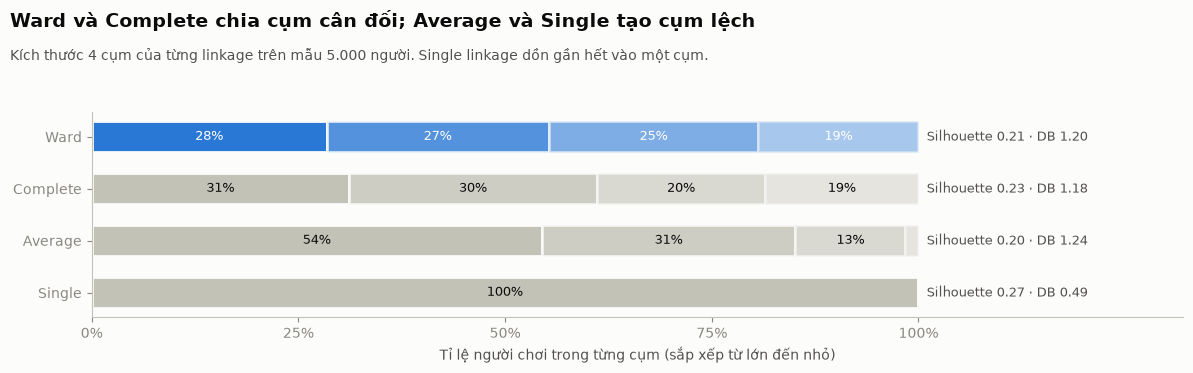

,silhouette,davies_bouldin,smallest_cluster
linkage,,,
ward,0.212,1.204,968
complete,0.229,1.182,927
average,0.200,1.239,79
single,0.273,0.494,1


In [10]:
link_rows, sizes = [], {}
for L in ['ward', 'complete', 'average', 'single']:
    h = AgglomerativeClustering(n_clusters=4, linkage=L).fit_predict(Xh)
    sizes[L] = np.sort(np.bincount(h))[::-1] / len(h)
    link_rows.append({'linkage': L, 'silhouette': silhouette_score(Xh, h), 'davies_bouldin': davies_bouldin_score(Xh, h),
                      'smallest_cluster': np.bincount(h).min()})
link_df = pd.DataFrame(link_rows).set_index('linkage')

fig, ax = plt.subplots(figsize=(12, 3.8))
order = ['ward', 'complete', 'average', 'single']
y = np.arange(len(order))[::-1]
for yy, L in zip(y, order):
    left = 0
    for j, s in enumerate(sizes[L]):
        ax.barh(yy, s, left=left, color=BLUE if L == 'ward' else GRAY, alpha=1 - 0.2 * j, edgecolor=SURFACE, linewidth=2, height=0.6)
        if s > 0.06: ax.text(left + s / 2, yy, f'{s:.0%}', ha='center', va='center', color='white' if L == 'ward' else INK, fontsize=9)
        left += s
    r = link_df.loc[L]
    ax.text(1.01, yy, f"Silhouette {r['silhouette']:.2f} · DB {r['davies_bouldin']:.2f}", va='center', color=INK2, fontsize=9)
ax.set_yticks(y, [o.capitalize() for o in order]); ax.set_xlim(0, 1.32); ax.grid(False)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1]); ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel('Tỉ lệ người chơi trong từng cụm (sắp xếp từ lớn đến nhỏ)')
finish(fig, '07_linkage_comparison', 'Ward và Complete chia cụm cân đối; Average và Single tạo cụm lệch',
       'Kích thước 4 cụm của từng linkage trên mẫu 5.000 người. Single linkage dồn gần hết vào một cụm.')
link_df.round(3)

**Kết luận:**
- **Single linkage** đạt Silhouette cao nhưng là **ảo**: gần như toàn bộ người chơi rơi vào một cụm, các cụm còn lại chỉ có 1 người. Silhouette cao vì vài điểm lẻ loi tách xa phần còn lại. Ví dụ điển hình cho việc **không thể chỉ nhìn một chỉ số**.
- **Average** tạo một cụm chiếm hơn nửa dữ liệu và một cụm rất nhỏ.
- **Ward** và **Complete** đều cho 4 cụm cân đối. Complete nhỉnh hơn một chút ở bước này (Silhouette 0,23 so với 0,21), nhưng khi dùng làm điểm khởi tạo cho K-Means thì hai lựa chọn cho kết quả cuối **gần như bằng nhau** (Silhouette 0,278 so với 0,276; DB 1,055 so với 1,059).
- Chọn **Ward** vì lý do lý thuyết: Ward gộp cụm sao cho **tổng phương sai trong cụm tăng ít nhất**, đúng hàm mục tiêu mà K-Means tối ưu. Tâm cụm Ward vì vậy là điểm khởi đầu nhất quán cho K-Means, và K-Means hội tụ nhanh hơn (14 vòng so với 19).

### 5.4 Chọn số cụm k

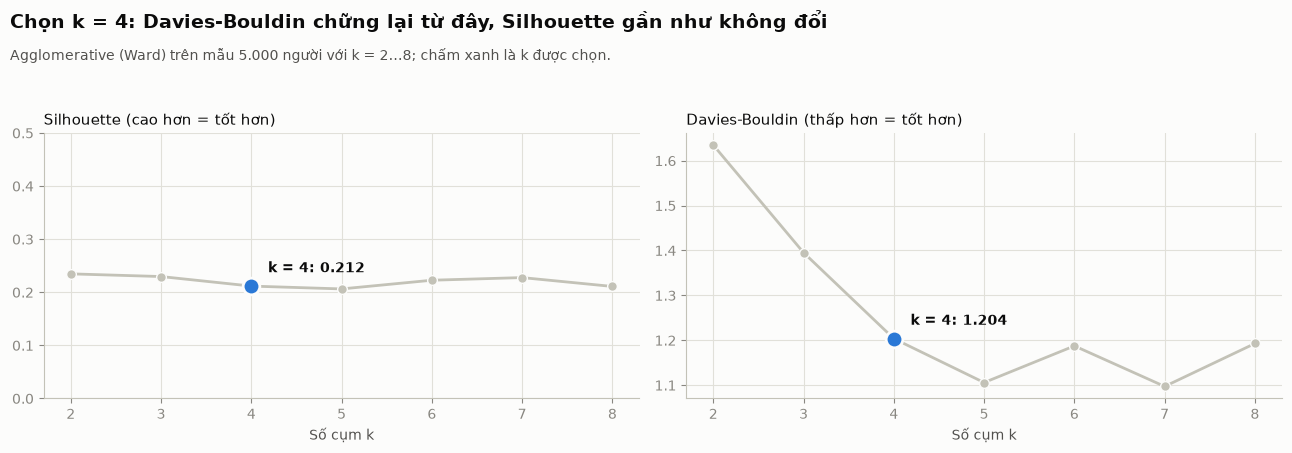

,silhouette,davies_bouldin
k,,
2,0.235,1.635
3,0.230,1.395
4,0.212,1.204
5,0.206,1.106
6,0.223,1.187
7,0.228,1.097
8,0.211,1.193


In [11]:
rows = []
for k in range(2, 9):
    h = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(Xh)
    rows.append({'k': k, 'silhouette': silhouette_score(Xh, h), 'davies_bouldin': davies_bouldin_score(Xh, h)})
hier_k = pd.DataFrame(rows).set_index('k')
K = 4

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for a, col, label in [(axes[0], 'silhouette', 'Silhouette (cao hơn = tốt hơn)'),
                      (axes[1], 'davies_bouldin', 'Davies-Bouldin (thấp hơn = tốt hơn)')]:
    s = hier_k[col]
    a.plot(s.index, s, color=GRAY, lw=2, marker='o', ms=7, mec=SURFACE)
    a.plot(K, s[K], 'o', ms=12, color=BLUE, mec=SURFACE, mew=2)
    a.annotate(f'k = {K}: {s[K]:.3f}', (K, s[K]), xytext=(12, 10), textcoords='offset points', color=INK, fontweight='bold')
    a.set_title(label); a.set_xlabel('Số cụm k'); a.set_xticks(hier_k.index)
axes[0].set_ylim(0, 0.5)  # full-ish scale: the flat curve is the honest message
finish(fig, '08_choose_k', f'Chọn k = {K}: Davies-Bouldin chững lại từ đây, Silhouette gần như không đổi',
       'Agglomerative (Ward) trên mẫu 5.000 người với k = 2…8; chấm xanh là k được chọn.')
hier_k.round(3)

**Quyết định: k = 4**
- **Silhouette** chỉ dao động trong khoảng hẹp (≈ 0,21–0,24), không phân định được k. Điều này khớp với Hopkins thấp: không có số cụm "tự nhiên" nổi bật.
- **Davies-Bouldin** giảm mạnh từ 1,64 (k=2) xuống 1,20 (k=4), sau đó dao động quanh 1,1–1,2: **điểm khuỷu** tại k = 4.
- k = 2 chỉ chia "chơi nhiều / chơi ít", quá thô để đặt chiến lược.
- **Về nghiệp vụ**, 4 phân khúc là số lượng đội marketing triển khai được.

### 5.5 Dendrogram

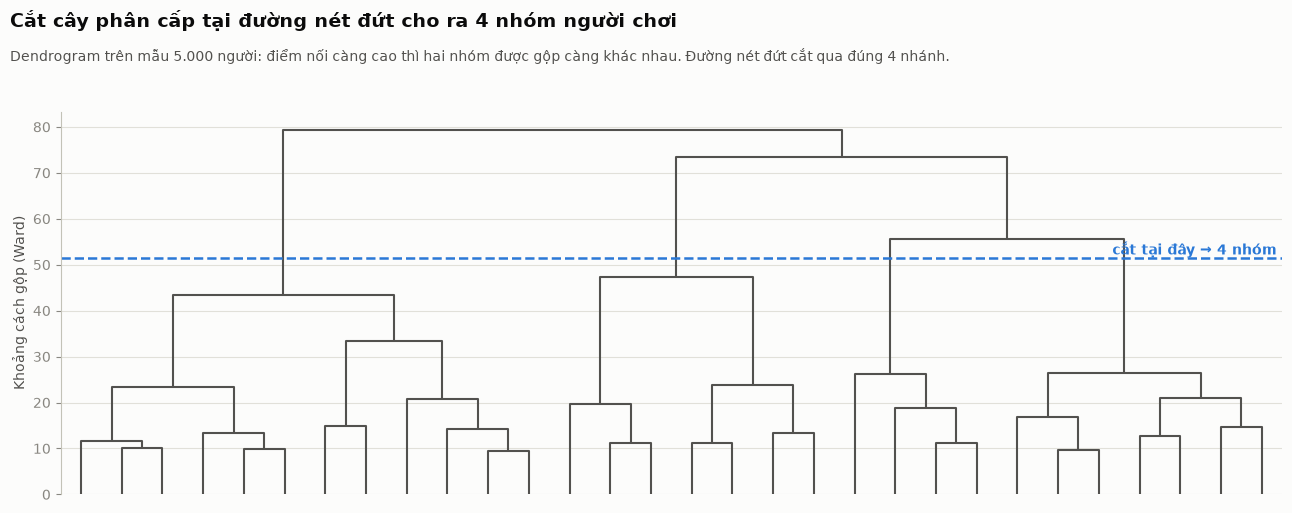

Last 8 merge distances (top of tree): [26.3 26.4 33.3 43.3 47.3 55.7 73.4 79.3]


In [12]:
Z = linkage(Xh, method='ward')
cut = (Z[-K, 2] + Z[-K + 1, 2]) / 2   # height between the merges that leave K and K-1 clusters
fig, ax = plt.subplots(figsize=(13, 5.2))
dendrogram(Z, truncate_mode='lastp', p=30, no_labels=True, color_threshold=0, above_threshold_color=INK2, ax=ax)
ax.axhline(cut, color=BLUE, ls='--', lw=1.8)
ax.text(ax.get_xlim()[1], cut, f'cắt tại đây → {K} nhóm ', color=BLUE, va='bottom', ha='right', fontweight='bold')
ax.set_ylabel('Khoảng cách gộp (Ward)'); ax.grid(axis='x', visible=False); ax.spines['bottom'].set_visible(False)
finish(fig, '09_dendrogram', f'Cắt cây phân cấp tại đường nét đứt cho ra {K} nhóm người chơi',
       'Dendrogram trên mẫu 5.000 người: điểm nối càng cao thì hai nhóm được gộp càng khác nhau. Đường nét đứt cắt qua đúng 4 nhánh.')
print('Last 8 merge distances (top of tree):', Z[-8:, 2].round(1))

**Cách đọc:** mỗi đường ngang là một lần gộp; độ cao là mức khác biệt giữa hai nhóm được gộp. Ba lần gộp cuối (≈ 56, 73, 79) cao hơn hẳn phần bên dưới, nên dữ liệu có vài nhóm lớn. Đường cắt cho k = 4 nằm giữa hai lần gộp liên tiếp. Khoảng trống không vượt trội so với các mức khác, nên quyết định k dựa vào chỉ số định lượng, dendrogram dùng để minh họa.

## 6. Phương pháp kết hợp: Agglomerative → K-Means

### 6.1 Vì sao kết hợp?
| | Agglomerative | K-Means |
|---|---|---|
| Ưu điểm | Không phụ thuộc khởi tạo ngẫu nhiên; dendrogram giúp chọn k | Nhanh, chạy được trên toàn bộ 40k điểm; tối ưu tâm cụm |
| Nhược điểm | Bộ nhớ $O(n^2)$; đã gộp thì không sửa lại được | Kết quả phụ thuộc điểm khởi tạo; phải biết trước k |

### 6.2 Quy trình
1. Agglomerative (Ward) trên mẫu 5.000 người với k = 4 → tính **tâm (centroid)** mỗi cụm.
2. Dùng 4 tâm làm **điểm khởi tạo** (`init`) cho K-Means trên **toàn bộ 40.034 người**.
3. K-Means lặp *gán điểm vào tâm gần nhất → cập nhật tâm* đến khi hội tụ, **sửa lại** các gán cụm chưa tối ưu của Agglomerative.

K-Means tối thiểu hóa **inertia** (tổng bình phương khoảng cách tới tâm cụm):
$$J = \sum_{i=1}^{n} \lVert x_i - c_{\text{cụm}(i)} \rVert^2$$
Vì khởi tạo đã có căn cứ, chỉ cần **một lần chạy** (`n_init=1`) và kết quả **xác định**.

In [13]:
h_labels = AgglomerativeClustering(n_clusters=K, linkage='ward').fit_predict(Xh)
centroids = np.array([Xh[h_labels == i].mean(axis=0) for i in range(K)])
hybrid_model = KMeans(n_clusters=K, init=centroids, n_init=1, random_state=SEED).fit(X)
df['Cluster'] = hybrid_model.labels_
print('K-Means iterations to converge:', hybrid_model.n_iter_)

scaler = StandardScaler().fit(df[FEATURES])
before = pd.DataFrame(scaler.inverse_transform(centroids), columns=FEATURES).round(1)
after = pd.DataFrame(scaler.inverse_transform(hybrid_model.cluster_centers_), columns=FEATURES).round(1)
display(pd.concat({'Agglomerative (init)': before, 'After K-Means': after}, axis=1))
df['Cluster'].value_counts().sort_index()

K-Means iterations to converge: 14


Agglomerative (init)                                    After K-Means  \
       WeeklyPlayHours PlayerLevel AchievementsUnlocked WeeklyPlayHours   
0                  9.0        45.2                  8.6             9.6   
1                 31.2        58.8                 24.3            36.1   
2                 10.9        28.0                 36.5            10.2   
3                  6.0        73.4                 30.6            10.2   

                                    
  PlayerLevel AchievementsUnlocked  
0        47.3                  9.1  
1        50.2                 23.4  
2        23.6                 34.8  
3        77.7                 33.3

Cluster
0    12059
1     7603
2    10101
3    10271
Name: count, dtype: int64

**Nhận xét:**
- K-Means hội tụ sau khoảng 14 vòng lặp. Bốn cụm cân đối (19%–30%).
- Mỗi cụm **giữ đặc trưng nổi bật** như lúc khởi tạo (giờ chơi cao / level cao / thành tựu cao / thành tựu thấp): **cấu trúc do Agglomerative tìm ra được giữ nguyên**.
- Nhưng tâm cụm **dịch chuyển đáng kể**: giờ chơi của cụm Hardcore tăng từ ≈ 31 lên ≈ 36 giờ/tuần, level của cụm level-cao tăng từ ≈ 73 lên ≈ 78. Agglomerative trên mẫu cho ranh giới còn thô; K-Means trên toàn bộ dữ liệu làm các cụm **tách bạch hơn**. Đây là đóng góp của bước K-Means.

## 7. Đánh giá chất lượng phân cụm

### 7.1 So sánh ba phương pháp
Cùng k = 4:
1. **Agglomerative đơn thuần** (mẫu 5k): đường cơ sở của phương pháp phân cấp.
2. **K-Means++** (khởi tạo ngẫu nhiên thông minh, 10 lần, giữ kết quả tốt nhất): đường cơ sở của K-Means.
3. **Hybrid** (đề xuất).

Thêm **Adjusted Rand Index (ARI)** để đo mức trùng khớp giữa hai cách phân cụm: 1 = giống hệt, 0 = trùng khớp như ngẫu nhiên.

Agreement Hybrid vs K-Means++ (ARI): 0.562


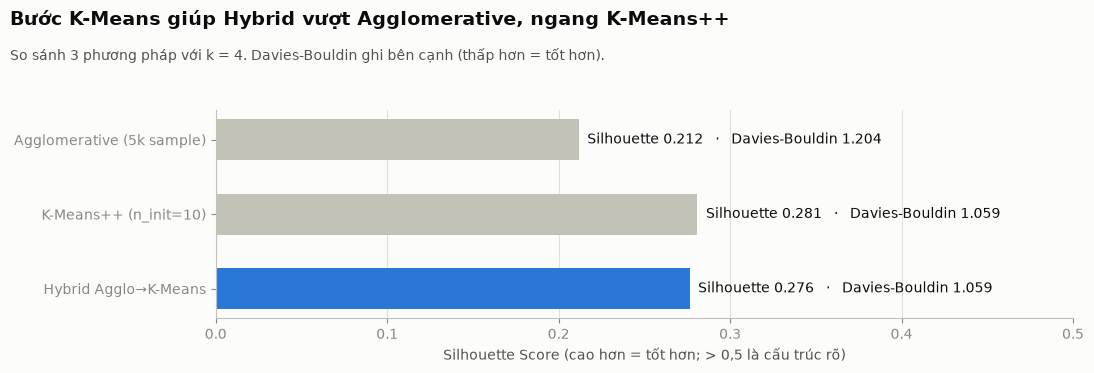

,silhouette,davies_bouldin,inertia,runs
method,,,,
Agglomerative (5k sample),0.212,1.204,NaN,1
K-Means++ (n_init=10),0.281,1.059,53342.697,10
Hybrid Agglo→K-Means,0.276,1.059,53461.573,1


In [14]:
kmpp = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X)
s_k, d_k = scores(kmpp.labels_)
s_y, d_y = scores(hybrid_model.labels_)
eval_df = pd.DataFrame({
    'method': ['Agglomerative (5k sample)', 'K-Means++ (n_init=10)', 'Hybrid Agglo→K-Means'],
    'silhouette': [silhouette_score(Xh, h_labels), s_k, s_y],
    'davies_bouldin': [davies_bouldin_score(Xh, h_labels), d_k, d_y],
    'inertia': [np.nan, kmpp.inertia_, hybrid_model.inertia_],
    'runs': [1, 10, 1],
}).set_index('method')
ari_kmpp = adjusted_rand_score(kmpp.labels_, hybrid_model.labels_)
print('Agreement Hybrid vs K-Means++ (ARI):', round(ari_kmpp, 3))

fig, ax = plt.subplots(figsize=(11, 3.8))
y = np.arange(len(eval_df))[::-1]
for a_y, (m, r) in zip(y, eval_df.iterrows()):
    ax.barh(a_y, r['silhouette'], color=BLUE if 'Hybrid' in m else GRAY, height=0.55)
    ax.text(r['silhouette'] + 0.005, a_y, f"Silhouette {r['silhouette']:.3f}   ·   Davies-Bouldin {r['davies_bouldin']:.3f}", va='center', color=INK)
ax.set_yticks(y, eval_df.index); ax.set_xlim(0, 0.5); ax.grid(axis='y', visible=False)
ax.set_xlabel('Silhouette Score (cao hơn = tốt hơn; > 0,5 là cấu trúc rõ)')
finish(fig, '10_method_comparison', 'Bước K-Means giúp Hybrid vượt Agglomerative, ngang K-Means++',
       f'So sánh 3 phương pháp với k = {K}. Davies-Bouldin ghi bên cạnh (thấp hơn = tốt hơn).')
eval_df.round(3)

**Phân tích:**
1. **Hybrid > Agglomerative đơn thuần:** Silhouette tăng từ ≈ 0,21 lên ≈ 0,28 (+30%), DB giảm từ ≈ 1,20 xuống ≈ 1,06 (−12%), nhờ K-Means sửa các lần gộp sai giai đoạn đầu.
2. **Hybrid ≈ K-Means++ về điểm số**, nhưng ARI giữa hai phương pháp chỉ ≈ **0,56**: **chia người chơi khác nhau đáng kể** dù điểm gần bằng nhau. Khi dữ liệu không có ranh giới tự nhiên rõ (Hopkins ≈ 0,58), **nhiều cách chia khác nhau "tốt như nhau"**. Mục 8 phân tích kỹ hiện tượng này.
   - Ưu điểm thực sự của Hybrid so với K-Means++: **một lần chạy thay vì 10**, và tâm khởi tạo **giải thích được** qua dendrogram (biết vì sao chọn 4 nhóm và mỗi nhóm bắt đầu từ đâu).
3. **Silhouette ≈ 0,28** thuộc mức *cấu trúc yếu–trung bình* (thang tham khảo: > 0,5 rõ; 0,25–0,5 yếu–trung bình; < 0,25 rất yếu), nhất quán với Hopkins.

### 7.2 Silhouette từng cụm
Silhouette trung bình che giấu sự khác biệt giữa các cụm. Tính silhouette của **từng người chơi** (mẫu 10.000) rồi lấy trung bình theo cụm, cùng tỉ lệ người có silhouette âm (có thể bị gán sai cụm). Kết quả theo tên phân khúc được hiển thị ở mục 9 (cột `silhouette`).

Chỉ ≈ 5% người chơi có silhouette âm: phần lớn được gán đúng cụm gần nhất. Đáng chú ý, nhóm **Hardcore có silhouette thấp nhất** (≈ 0,19) dù là nhóm ổn định nhất (mục 8): nhóm này tách biệt rõ theo giờ chơi, nhưng bên trong lại trải rộng theo level và thành tựu, nên kém "gọn". Silhouette đo độ gọn, không đo độ ổn định; hai chỉ số bổ sung cho nhau.

In [15]:
ss = silhouette_samples(X[idx_s], hybrid_model.labels_[idx_s])
lab_s = hybrid_model.labels_[idx_s]
per_cluster = pd.Series({c: ss[lab_s == c].mean() for c in range(K)})
print('Mean silhouette per cluster:', per_cluster.round(3).to_dict(), '| share negative:', round((ss < 0).mean(), 3))

Mean silhouette per cluster: {0: 0.252, 1: 0.186, 2: 0.337, 3: 0.312} | share negative: 0.046


## 8. Độ ổn định: phân khúc nào là "thật"?

ARI 0,56 ở mục 7 đặt ra câu hỏi: nếu lấy **mẫu 5.000 người khác**, Hybrid có ra cùng các phân khúc không?

**Thí nghiệm:** chạy lại Hybrid với **10 mẫu khác nhau**, và (để so sánh) K-Means khởi tạo ngẫu nhiên với 10 seed khác nhau. Với mỗi lần chạy, đo:
- **ARI** so với kết quả chính (seed 42);
- **Silhouette**;
- **Độ trùng khớp nhóm Hardcore** (Jaccard: số người chung / số người thuộc ít nhất một trong hai), với Hardcore là cụm có giờ chơi trung bình cao nhất.

In [16]:
ref = hybrid_model.labels_
ref_hc = ref == np.argmax(hybrid_model.cluster_centers_[:, 0])

def hardcore_jaccard(model):
    hc = model.labels_ == np.argmax(model.cluster_centers_[:, 0])
    return (hc & ref_hc).sum() / (hc | ref_hc).sum()

stab_rows, centroid_rows = [], []
for s in range(10):
    idx = np.random.default_rng(100 + s).choice(len(X), 5000, replace=False)
    for method, m in [('Hybrid (mẫu khác)', hybrid(X, K, idx)),
                      ('K-Means khởi tạo ngẫu nhiên', KMeans(n_clusters=K, init='random', n_init=1, random_state=s).fit(X))]:
        stab_rows.append({'method': method, 'run': s, 'ari_vs_main': adjusted_rand_score(ref, m.labels_),
                          'silhouette': silhouette_score(X[idx_s], m.labels_[idx_s]), 'hardcore_jaccard': hardcore_jaccard(m)})
        if method.startswith('Hybrid'):
            for c in scaler.inverse_transform(m.cluster_centers_):
                centroid_rows.append({'run': s, 'hours': c[0], 'level': c[1], 'achievements': c[2]})
stab = pd.DataFrame(stab_rows); cents = pd.DataFrame(centroid_rows)
display(stab.groupby('method')[['ari_vs_main', 'silhouette', 'hardcore_jaccard']].agg(['mean', 'min', 'max']).round(3))

ari_vs_main               silhouette         \
                                   mean    min    max       mean    min   
method                                                                    
Hybrid (mẫu khác)                 0.500  0.376  0.900      0.279  0.276   
K-Means khởi tạo ngẫu nhiên       0.634  0.449  0.907      0.278  0.276   

                                   hardcore_jaccard                
                               max             mean    min    max  
method                                                             
Hybrid (mẫu khác)            0.281            0.848  0.805  0.963  
K-Means khởi tạo ngẫu nhiên  0.281            0.889  0.834  0.965

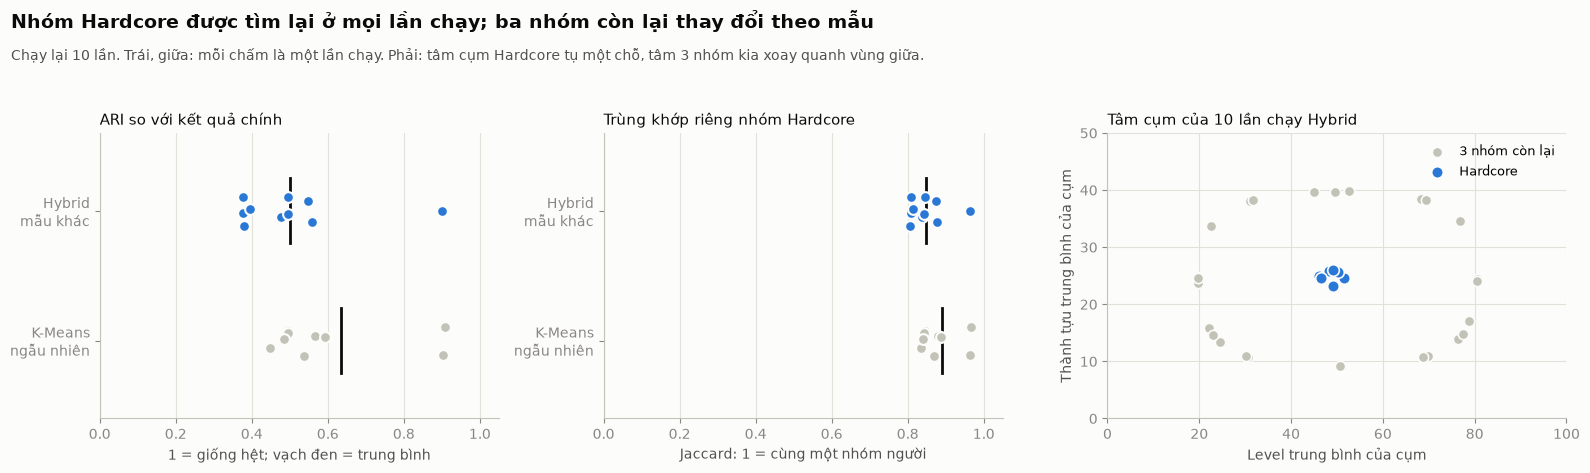

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={'width_ratios': [1, 1, 1.15]})
methods = ['Hybrid (mẫu khác)', 'K-Means khởi tạo ngẫu nhiên']
for a, col, title in [(axes[0], 'ari_vs_main', 'ARI so với kết quả chính'),
                      (axes[1], 'hardcore_jaccard', 'Trùng khớp riêng nhóm Hardcore')]:
    for yy, m in enumerate(methods[::-1]):
        v = stab.loc[stab['method'] == m, col]
        a.scatter(v, np.full(len(v), yy) + np.random.default_rng(yy).uniform(-0.12, 0.12, len(v)),
                  s=60, color=BLUE if m.startswith('Hybrid') else GRAY, edgecolor=SURFACE, linewidth=1.5, zorder=3)
        a.plot([v.mean()] * 2, [yy - 0.25, yy + 0.25], color=INK, lw=2)
    a.set_yticks([0, 1], ['K-Means\nngẫu nhiên', 'Hybrid\nmẫu khác']); a.set_xlim(0, 1.05)
    a.set_title(title); a.grid(axis='y', visible=False); a.set_ylim(-0.6, 1.6)
axes[0].set_xlabel('1 = giống hệt; vạch đen = trung bình'); axes[1].set_xlabel('Jaccard: 1 = cùng một nhóm người')

a = axes[2]
hc = cents['hours'] > 25
a.scatter(cents.loc[~hc, 'level'], cents.loc[~hc, 'achievements'], s=55, color=GRAY, edgecolor=SURFACE, linewidth=1.2, label='3 nhóm còn lại')
a.scatter(cents.loc[hc, 'level'], cents.loc[hc, 'achievements'], s=70, color=BLUE, edgecolor=SURFACE, linewidth=1.2, label='Hardcore')
a.set_xlim(0, 100); a.set_ylim(0, 50); a.set_xlabel('Level trung bình của cụm'); a.set_ylabel('Thành tựu trung bình của cụm')
a.set_title('Tâm cụm của 10 lần chạy Hybrid'); a.legend(loc='upper right', fontsize=9)
finish(fig, '11_stability', 'Nhóm Hardcore được tìm lại ở mọi lần chạy; ba nhóm còn lại thay đổi theo mẫu',
       'Chạy lại 10 lần. Trái, giữa: mỗi chấm là một lần chạy. Phải: tâm cụm Hardcore tụ một chỗ, tâm 3 nhóm kia xoay quanh vùng giữa.')

**Đây là phát hiện quan trọng nhất của nghiên cứu:**
- **Nhóm Hardcore** được tìm lại ở **mọi** lần chạy, với cả hai phương pháp: trùng khớp trung bình ≈ 85% số người (Jaccard 0,80–0,96), và tâm cụm tụ về cùng một chỗ (level ≈ 49, thành tựu ≈ 25). Đây là phân khúc **thật**: những người chơi trên ~25 giờ/tuần tách khỏi phần còn lại theo trục giờ chơi. Phần ~15% không trùng là người chơi ở ranh giới 20–25 giờ/tuần.
- **Ba nhóm còn lại** đều chơi ≈ 10 giờ/tuần và chỉ khác nhau về level và thành tựu. Nhưng level và thành tựu **phân bố đều và độc lập** (mục 1–2), nên vùng này là một "hình vuông" đồng đều không có ranh giới tự nhiên. Mỗi lần chạy cắt hình vuông theo một cách khác nhau, nên tâm cụm **xoay vòng** (biểu đồ phải) và ARI toàn cục dao động mạnh.
- Silhouette **gần như không đổi** giữa các lần chạy (≈ 0,28): mọi cách cắt đều "tốt như nhau".
- **Một kết quả trung thực về Hybrid:** khi đổi mẫu 5.000 người, kết quả Hybrid dao động **không ít hơn** K-Means khởi tạo ngẫu nhiên (ARI trung bình 0,50 so với 0,63). Nghĩa là Hybrid chỉ **xác định khi cố định mẫu**; nó không làm cho phân cụm ổn định hơn, vì sự bất ổn nằm ở **dữ liệu**, không ở thuật toán. Giá trị của Hybrid là **tiết kiệm (1 lần chạy)** và **giải thích được**, không phải ổn định hơn.

**Hàm ý cho kinh doanh:**
- Chiến lược cho **Hardcore** đáng tin cậy nhất.
- Ba nhóm còn lại nên hiểu là **cách chia thuận tiện** một tập người chơi tương đối đồng nhất theo hai trục *tiến trình (level)* và *sưu tập (thành tựu)*. Tên nhóm phản ánh vị trí trên hai trục này, không phải loại người chơi có ranh giới rõ.

## 9. Hồ sơ người chơi (Player profiling)

Tính giá trị trung bình của từng đặc trưng trong mỗi cụm (đơn vị gốc), kèm các biến **không dùng để phân cụm** (mua hàng, engagement, tuổi) để mô tả và kiểm chứng.

**Cách đặt tên:** theo đặc trưng **nổi bật nhất**: giờ chơi cao nhất → *Hardcore*; level cao nhất → *Veteran Grinders*; thành tựu cao nhất → *Achievement Hunters*; cụm còn lại → *Casual*.

In [18]:
profile = df.groupby('Cluster').agg(
    players=('PlayerID', 'size'),
    weekly_hours=('WeeklyPlayHours', 'mean'),
    level=('PlayerLevel', 'mean'),
    achievements=('AchievementsUnlocked', 'mean'),
    purchase_rate=('InGamePurchases', 'mean'),
    high_engagement=('EngagementLevel', lambda s: (s == 'High').mean()),
    age=('Age', 'mean'),
)
profile['share'] = profile['players'] / len(df)

# Name greedily by dominant trait; leftover clusters are Casual.
# shortcut: assumes K=4 with one standout trait per cluster; rename manually if K changes.
names = {}
for col, label in [('weekly_hours', 'Hardcore'), ('level', 'Veteran Grinders'), ('achievements', 'Achievement Hunters')]:
    names[profile.drop(index=list(names))[col].idxmax()] = label
names = {c: names.get(c, 'Casual') for c in profile.index}
profile.insert(0, 'segment', profile.index.map(names))
df['Segment'] = df['Cluster'].map(names)
profile['silhouette'] = profile.index.map(per_cluster)
profile.round(2)

,segment,players,weekly_hours,level,achievements,purchase_rate,high_engagement,age,share,silhouette
Cluster,,,,,,,,,,
0,Casual,12059,9.60,47.39,9.13,0.2,0.08,32.00,0.30,0.25
1,Hardcore,7603,36.14,50.13,23.38,0.2,0.92,31.98,0.19,0.19
2,Achievement Hunters,10101,10.23,23.50,34.78,0.2,0.11,31.95,0.25,0.34
3,Veteran Grinders,10271,10.23,77.69,33.37,0.2,0.13,32.03,0.26,0.31


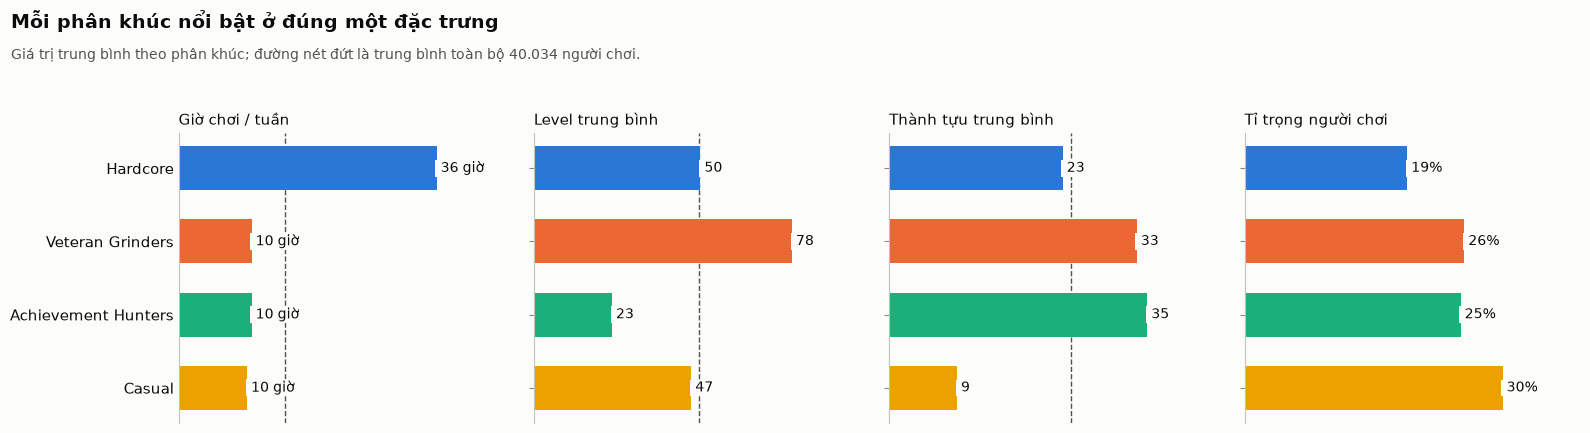

In [19]:
p = profile.set_index('segment').loc[SEG_ORDER]
y = np.arange(K)[::-1]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4), sharey=True)
panels = [('weekly_hours', 'Giờ chơi / tuần', '{:.0f} giờ'), ('level', 'Level trung bình', '{:.0f}'),
          ('achievements', 'Thành tựu trung bình', '{:.0f}'), ('share', 'Tỉ trọng người chơi', '{:.0%}')]
overall = {'weekly_hours': df['WeeklyPlayHours'].mean(), 'level': df['PlayerLevel'].mean(),
           'achievements': df['AchievementsUnlocked'].mean()}
for a, (col, title, fmt) in zip(axes, panels):
    v = p[col]
    a.barh(y, v, color=[SEG_COLORS[s] for s in SEG_ORDER], height=0.6)
    for yy, val in zip(y, v):
        a.text(val, yy, ' ' + fmt.format(val), va='center', color=INK, bbox=dict(fc=SURFACE, ec='none', pad=1))
    if col in overall:
        a.axvline(overall[col], color=INK2, ls='--', lw=1, zorder=0)
    a.set_title(title); a.set_xlim(0, v.max() * 1.3); a.set_xticks([]); a.grid(False); a.spines['bottom'].set_visible(False)
axes[0].set_yticks(y, SEG_ORDER); axes[0].tick_params(axis='y', length=0, labelsize=11, labelcolor=INK)
finish(fig, '12_segment_profiles', 'Mỗi phân khúc nổi bật ở đúng một đặc trưng',
       'Giá trị trung bình theo phân khúc; đường nét đứt là trung bình toàn bộ 40.034 người chơi.')

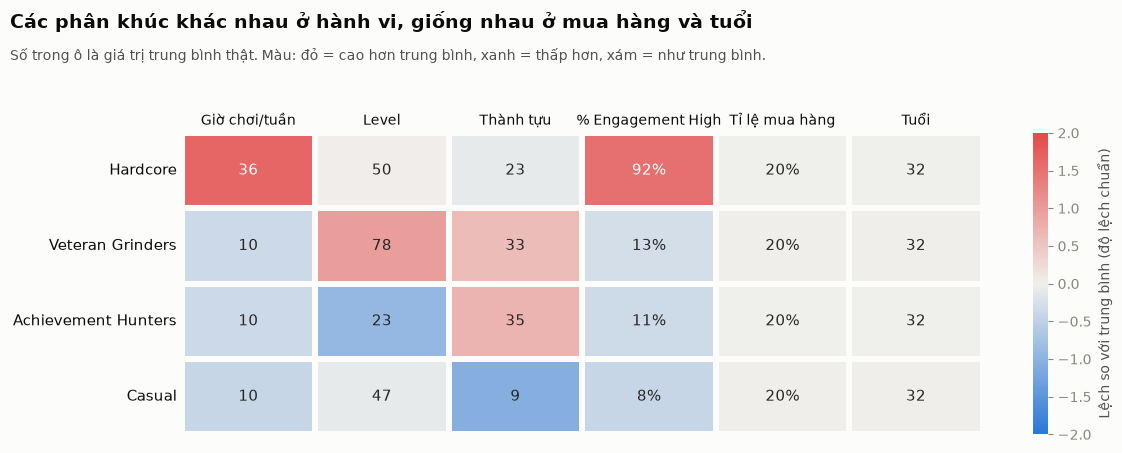

In [20]:
# Fingerprint: how far each segment sits from the average player, in standard deviations
cols = {'WeeklyPlayHours': 'Giờ chơi/tuần', 'PlayerLevel': 'Level', 'AchievementsUnlocked': 'Thành tựu',
        'HighEng': '% Engagement High', 'InGamePurchases': 'Tỉ lệ mua hàng', 'Age': 'Tuổi'}
tmp = df.assign(HighEng=(df['EngagementLevel'] == 'High').astype(float))
means = tmp.groupby('Segment')[list(cols)].mean().loc[SEG_ORDER]
z = (means - tmp[list(cols)].mean()) / tmp[list(cols)].std()
annot = means.copy().astype(object)
for c in cols:
    annot[c] = means[c].map('{:.0%}'.format) if c in ('HighEng', 'InGamePurchases') else means[c].map('{:.0f}'.format)
fig, ax = plt.subplots(figsize=(12, 4.6))
sns.heatmap(z.rename(columns=cols), annot=annot.values, fmt='', cmap=DIVERGING, vmin=-2, vmax=2,
            linewidths=3, linecolor=SURFACE, cbar_kws={'label': 'Lệch so với trung bình (độ lệch chuẩn)'},
            annot_kws={'fontsize': 11}, ax=ax)
ax.grid(False); ax.tick_params(length=0); ax.set_xlabel(''); ax.set_ylabel('')
ax.xaxis.tick_top(); plt.setp(ax.get_yticklabels(), rotation=0, color=INK, fontsize=11)
plt.setp(ax.get_xticklabels(), color=INK)
finish(fig, '13_segment_fingerprint', 'Các phân khúc khác nhau ở hành vi, giống nhau ở mua hàng và tuổi',
       'Số trong ô là giá trị trung bình thật. Màu: đỏ = cao hơn trung bình, xanh = thấp hơn, xám = như trung bình.')

### Mô tả từng phân khúc

**Hardcore (≈ 19%)**: chơi khoảng **36 giờ/tuần**, gấp 3,5 lần các nhóm khác; level và thành tựu trung bình. **92%** có engagement High, nên nhãn có sẵn **xác nhận độc lập** đây là nhóm gắn bó nhất (nhãn engagement không được dùng khi phân cụm). Phân khúc **ổn định nhất** (mục 8).

**Veteran Grinders (≈ 26%)**: level cao nhất (≈ **78**), nhiều thành tựu, nhưng chỉ ≈ 10 giờ/tuần. Người chơi **lâu năm**: tích lũy tiến trình qua thời gian dài chứ không chơi dồn dập.

**Achievement Hunters (≈ 25%)**: level thấp (≈ **23**) nhưng **nhiều thành tựu nhất** (≈ 35). Người chơi mới hoặc trung bình có động lực **hoàn thành mục tiêu, sưu tập**.

**Casual (≈ 30%, đông nhất)**: ít thành tựu nhất (≈ 9), giờ chơi thấp, engagement High chỉ 8%. Chơi giải trí, chưa gắn bó.

**Dấu vân tay** (heatmap): ba cột hành vi có màu đậm khác nhau giữa các nhóm; cột *mua hàng* và *tuổi* gần như xám ở mọi nhóm. Các phân khúc khác nhau **thuần túy ở hành vi chơi**.

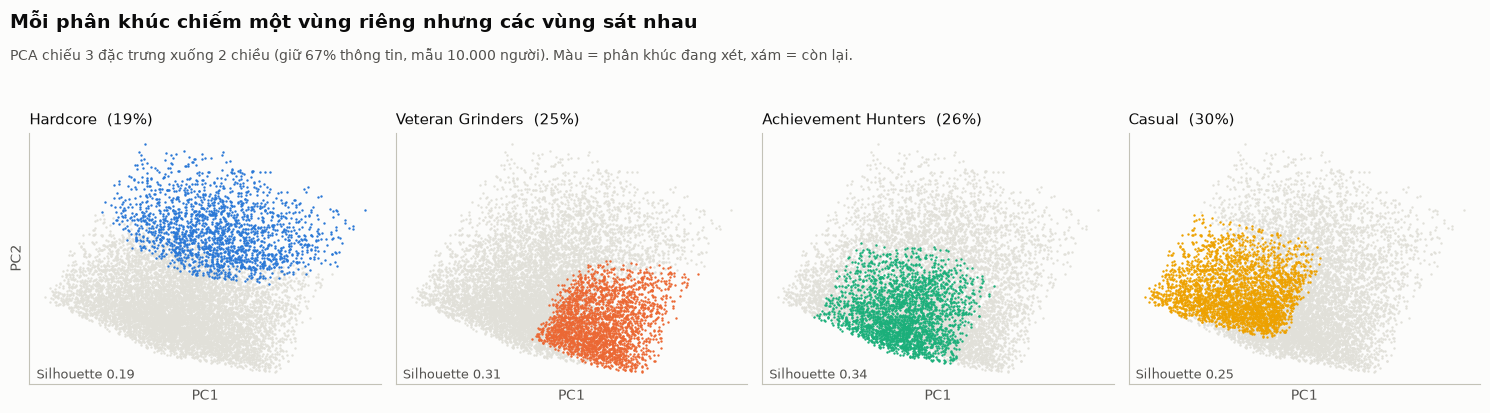

In [21]:
P = PCA(2, random_state=SEED).fit(X)
P2 = P.transform(X[idx_s])
seg_s = df['Segment'].values[idx_s]
fig, axes = plt.subplots(1, K, figsize=(15, 4.2), sharex=True, sharey=True)
for a, c in zip(axes, SEG_ORDER):
    m = seg_s == c
    a.scatter(P2[~m, 0], P2[~m, 1], s=3, color=GRID, linewidths=0)
    a.scatter(P2[m, 0], P2[m, 1], s=3, color=SEG_COLORS[c], linewidths=0)
    a.set_title(f'{c}  ({m.mean():.0%})'); a.set_xticks([]); a.set_yticks([])
    a.text(0.02, 0.02, f'Silhouette {ss[m].mean():.2f}', transform=a.transAxes, color=INK2, fontsize=9)
axes[0].set_ylabel('PC2'); [a.set_xlabel('PC1') for a in axes]
finish(fig, '14_pca_clusters', 'Mỗi phân khúc chiếm một vùng riêng nhưng các vùng sát nhau',
       f'PCA chiếu 3 đặc trưng xuống 2 chiều (giữ {P.explained_variance_ratio_.sum():.0%} thông tin, mẫu 10.000 người). Màu = phân khúc đang xét, xám = còn lại.')

**Đọc biểu đồ PCA:** mỗi phân khúc chiếm một vùng riêng nhưng các vùng **tiếp giáp**, không có khoảng trống giữa chúng, minh họa trực quan cho Silhouette vừa phải. Hardcore nằm tách lên phía trên (theo trục giờ chơi); ba nhóm kia chia nhau phần dưới. Silhouette từng nhóm ghi ở góc mỗi khung.

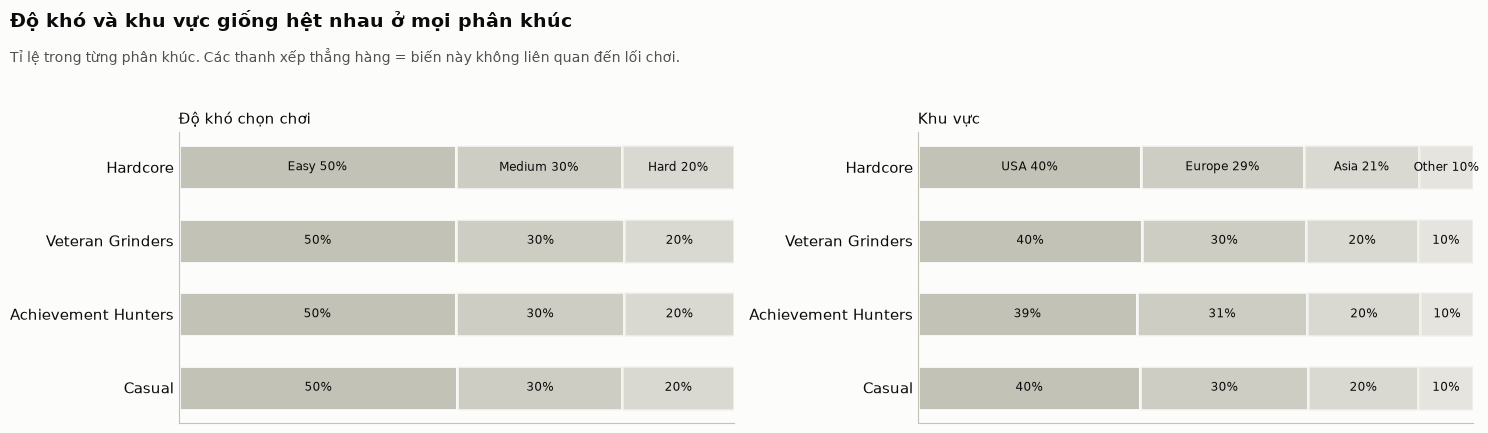

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
pd_ = pd.crosstab(df['Segment'], df['GameDifficulty'], normalize='index').loc[SEG_ORDER, ['Easy', 'Medium', 'Hard']]
pg = pd.crosstab(df['Segment'], df['Location'], normalize='index').loc[SEG_ORDER, ['USA', 'Europe', 'Asia', 'Other']]
for a, tab, title in [(axes[0], pd_, 'Độ khó chọn chơi'), (axes[1], pg, 'Khu vực')]:
    left = np.zeros(K); yy = np.arange(K)[::-1]
    for j, c in enumerate(tab.columns):
        a.barh(yy, tab[c], left=left, color=GRAY, alpha=1 - 0.2 * j, edgecolor=SURFACE, linewidth=2, height=0.6)
        for y_, l_, v_ in zip(yy, left, tab[c]):
            if v_ > 0.08: a.text(l_ + v_ / 2, y_, f'{c} {v_:.0%}' if y_ == K - 1 else f'{v_:.0%}', ha='center', va='center', color=INK, fontsize=8.5)
        left += tab[c].values
    a.set_yticks(yy, SEG_ORDER); a.set_xlim(0, 1); a.set_xticks([]); a.grid(False); a.set_title(title)
    a.tick_params(axis='y', length=0, labelsize=10.5, labelcolor=INK)
finish(fig, '15_segment_demographics', 'Độ khó và khu vực giống hệt nhau ở mọi phân khúc',
       'Tỉ lệ trong từng phân khúc. Các thanh xếp thẳng hàng = biến này không liên quan đến lối chơi.')

## 10. Phân tích chi tiêu: có nhóm High-Spender không?

Đề bài gợi ý một nhóm *High-Spenders*. Kiểm tra tỉ lệ mua hàng theo phân khúc, rồi dùng **kiểm định Chi-bình phương (χ²)** để biết khác biệt (nếu có) là thật hay do ngẫu nhiên.

- **Giả thuyết H₀:** tỉ lệ mua hàng như nhau ở mọi phân khúc.
- Nếu p-value < 0,05 thì bác bỏ H₀ (có khác biệt có ý nghĩa thống kê).

Chi-square = 3.21, df = 3, p-value = 0.361


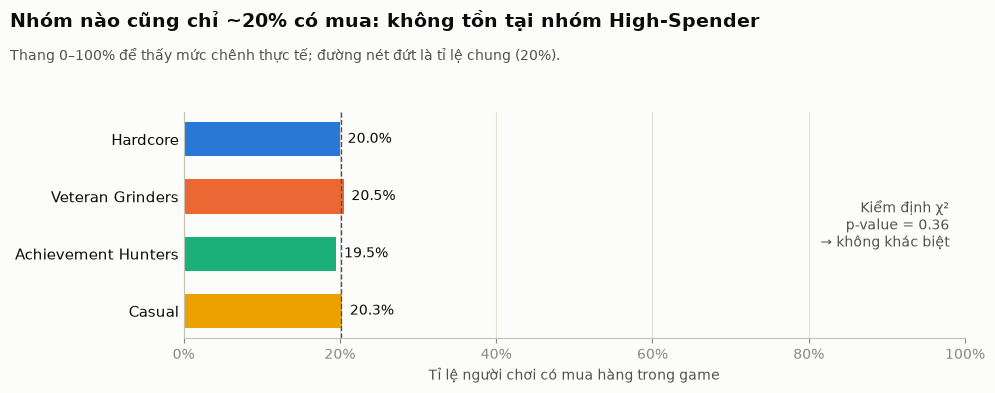

In [23]:
chi2, p_value, dof, _ = chi2_contingency(pd.crosstab(df['Segment'], df['InGamePurchases']))
print(f'Chi-square = {chi2:.2f}, df = {dof}, p-value = {p_value:.3f}')

pr = profile.set_index('segment').loc[SEG_ORDER, 'purchase_rate']
fig, ax = plt.subplots(figsize=(10, 4))
yb = np.arange(K)[::-1]
ax.barh(yb, pr, color=[SEG_COLORS[s] for s in SEG_ORDER], height=0.6)
label_bars(ax, pr, yb, '{:.1%}')
ax.axvline(df['InGamePurchases'].mean(), color=INK2, ls='--', lw=1)
ax.set_yticks(yb, SEG_ORDER); ax.tick_params(axis='y', length=0, labelsize=11, labelcolor=INK)
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.grid(axis='y', visible=False)
ax.set_xlabel('Tỉ lệ người chơi có mua hàng trong game')
ax.text(0.98, 0.5, f'Kiểm định χ²\np-value = {p_value:.2f}\n→ không khác biệt', transform=ax.transAxes, ha='right', va='center', color=INK2)
finish(fig, '16_purchase_rate', 'Nhóm nào cũng chỉ ~20% có mua: không tồn tại nhóm High-Spender',
       'Thang 0–100% để thấy mức chênh thực tế; đường nét đứt là tỉ lệ chung (20%).')

**Kết luận:**
- Tỉ lệ mua hàng **≈ 20% ở mọi phân khúc** (19,5%–20,5%), p-value ≈ 0,36 > 0,05: **không bác bỏ H₀**. Hành vi chơi **không liên quan** đến việc có chi tiền hay không trong dataset này.
- `InGamePurchases` chỉ là cờ 0/1, **không có số tiền**, nên không phân biệt được người chi nhiều với chi ít.

→ **Không thể xác định nhóm High-Spender** từ dữ liệu này. Phát hiện này có giá trị: doanh nghiệp **không nên giả định người chơi nhiều thì chi nhiều**. Chiến lược bên dưới vì vậy tập trung vào **tăng tỉ lệ chuyển đổi** trong từng nhóm; ~20% người đã mua trong mỗi nhóm là tập *spenders* để chăm sóc riêng.

## 11. Mô hình bổ sung

Ba câu hỏi còn bỏ ngỏ sau phân cụm, mỗi câu được trả lời bằng một mô hình:

| Câu hỏi | Mô hình | Loại |
|---|---|---|
| Ranh giới giữa các nhóm "mềm" đến mức nào? | **Gaussian Mixture Model (GMM)** | Phân cụm mềm |
| Làm sao xếp người chơi **mới** vào phân khúc mà không chạy lại phân cụm? | **Cây quyết định** | Phân loại có giám sát |
| Các phát hiện về engagement và mua hàng có đứng vững khi dùng mô hình mạnh? | **Gradient Boosting** | Phân loại có giám sát |

### 11.1 Gaussian Mixture Model: phân cụm mềm
K-Means gán mỗi người vào **đúng một** nhóm. GMM giả định dữ liệu sinh ra từ $k$ phân phối chuẩn và cho mỗi người **xác suất thuộc từng nhóm** $P(\text{nhóm } j \mid x)$. Người có xác suất cao nhất dưới 0,7 được xem là **nằm ở vùng giáp ranh**.

GMM silhouette = 0.213 | ARI vs Hybrid = 0.349 | share with max probability < 0.7 = 20.1%


,WeeklyPlayHours,PlayerLevel,AchievementsUnlocked
GMM component,,,
0,6.3,39.2,11.7
1,10.0,85.3,24.5
2,27.6,45.3,24.6
3,6.3,39.3,37.3


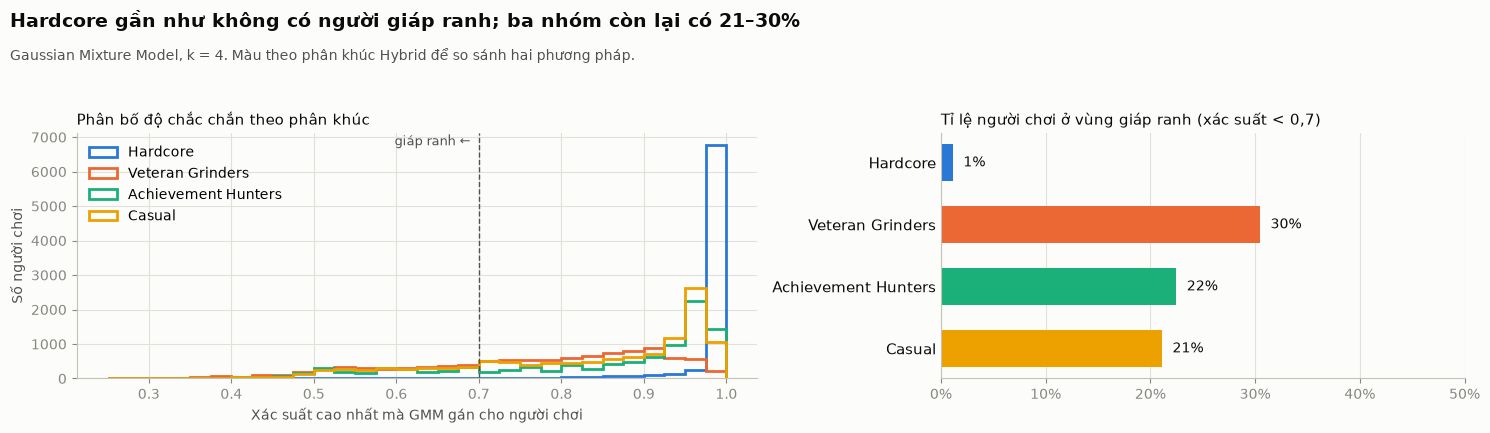

In [24]:
gmm = GaussianMixture(n_components=K, random_state=SEED, n_init=3).fit(X)
proba = gmm.predict_proba(X)
max_p = proba.max(axis=1)
df['GMM_MaxProb'] = max_p
uncertain = (df.assign(u=max_p < 0.7).groupby('Segment')['u'].mean()).loc[SEG_ORDER]
gmm_labels = gmm.predict(X)
print(f'GMM silhouette = {silhouette_score(X[idx_s], gmm_labels[idx_s]):.3f} | '
      f'ARI vs Hybrid = {adjusted_rand_score(hybrid_model.labels_, gmm_labels):.3f} | '
      f'share with max probability < 0.7 = {(max_p < 0.7).mean():.1%}')
display(pd.DataFrame(scaler.inverse_transform(gmm.means_), columns=FEATURES).round(1).rename_axis('GMM component'))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw={'width_ratios': [1.3, 1]})
a = axes[0]
bins = np.linspace(0.25, 1, 31)
for c in SEG_ORDER:
    a.hist(df.loc[df['Segment'] == c, 'GMM_MaxProb'], bins=bins, histtype='step', lw=2, color=SEG_COLORS[c], label=c)
a.axvline(0.7, color=INK2, ls='--', lw=1); a.text(0.69, a.get_ylim()[1] * 0.95, 'giáp ranh ←', ha='right', color=INK2, fontsize=9)
a.set_xlabel('Xác suất cao nhất mà GMM gán cho người chơi'); a.set_ylabel('Số người chơi')
a.set_title('Phân bố độ chắc chắn theo phân khúc'); a.legend(loc='upper left')
a = axes[1]
yb = np.arange(K)[::-1]
a.barh(yb, uncertain, color=[SEG_COLORS[c] for c in SEG_ORDER], height=0.6)
label_bars(a, uncertain, yb, '{:.0%}')
a.set_yticks(yb, SEG_ORDER); a.tick_params(axis='y', length=0, labelsize=10.5, labelcolor=INK)
a.set_xlim(0, 0.5); a.xaxis.set_major_formatter(PercentFormatter(1)); a.grid(axis='y', visible=False)
a.set_title('Tỉ lệ người chơi ở vùng giáp ranh (xác suất < 0,7)')
finish(fig, '17_gmm_uncertainty', 'Hardcore gần như không có người giáp ranh; ba nhóm còn lại có 21–30%',
       'Gaussian Mixture Model, k = 4. Màu theo phân khúc Hybrid để so sánh hai phương pháp.')

**Kết luận:**
- Khoảng **20%** người chơi nằm ở vùng giáp ranh. Con số này đo trực tiếp mức "mềm" của ranh giới.
- **Hardcore chỉ ≈ 1%** giáp ranh, trong khi ba nhóm kia **21–30%**. GMM, một phương pháp hoàn toàn khác, **xác nhận độc lập** kết quả phân tích độ ổn định ở mục 8: Hardcore là nhóm tách biệt rõ, ba nhóm còn lại chia nhau một vùng liên tục.
- Silhouette của GMM (≈ 0,21) thấp hơn Hybrid (≈ 0,28), và hai phương pháp chia khá khác nhau (ARI ≈ 0,35). Hybrid vẫn là phương pháp chính; GMM dùng để **định lượng độ không chắc chắn**.
- **Ứng dụng:** người chơi giáp ranh nên nhận ưu đãi kết hợp của hai nhóm lân cận thay vì một chiến lược cứng.

### 11.2 Cây quyết định: quy tắc xếp người chơi mới vào phân khúc
Lấy phân khúc tìm được làm **nhãn**, huấn luyện cây quyết định trên 3 đặc trưng gốc (không cần chuẩn hóa). Chia 80% huấn luyện / 20% kiểm tra, thử độ sâu 2–6. Cây nông thì dễ đọc nhưng kém chính xác; cây sâu thì ngược lại.

|--- AchievementsUnlocked <= 18.5
|   |--- WeeklyPlayHours <= 26.1
|   |   |--- AchievementsUnlocked <= 14.5
|   |   |   |--- class: Casual
|   |   |--- AchievementsUnlocked >  14.5
|   |   |   |--- class: Casual
|   |--- WeeklyPlayHours >  26.1
|   |   |--- WeeklyPlayHours <= 28.6
|   |   |   |--- class: Hardcore
|   |   |--- WeeklyPlayHours >  28.6
|   |   |   |--- class: Hardcore
|--- AchievementsUnlocked >  18.5
|   |--- PlayerLevel <= 51.5
|   |   |--- WeeklyPlayHours <= 26.6
|   |   |   |--- class: Achievement Hunters
|   |   |--- WeeklyPlayHours >  26.6
|   |   |   |--- class: Hardcore
|   |--- PlayerLevel >  51.5
|   |   |--- WeeklyPlayHours <= 27.5
|   |   |   |--- class: Veteran Grinders
|   |   |--- WeeklyPlayHours >  27.5
|   |   |   |--- class: Hardcore



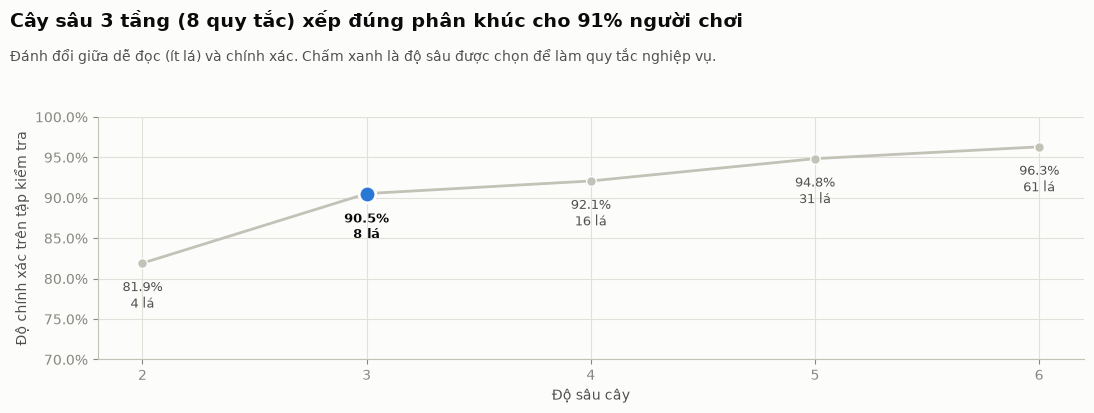

,test_accuracy,leaves
depth,,
2,0.819,4
3,0.905,8
4,0.921,16
5,0.948,31
6,0.963,61


In [25]:
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import train_test_split

Xtr, Xte, ytr, yte = train_test_split(df[FEATURES], df['Segment'], test_size=0.2, stratify=df['Segment'], random_state=SEED)
depth_rows = []
for d in range(2, 7):
    t = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(Xtr, ytr)
    depth_rows.append({'depth': d, 'test_accuracy': t.score(Xte, yte), 'leaves': t.get_n_leaves()})
depth_df = pd.DataFrame(depth_rows).set_index('depth')
TREE_DEPTH = 3
tree = DecisionTreeClassifier(max_depth=TREE_DEPTH, random_state=SEED).fit(Xtr, ytr)
print(export_text(tree, feature_names=['WeeklyPlayHours', 'PlayerLevel', 'AchievementsUnlocked'], decimals=1))

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(depth_df.index, depth_df['test_accuracy'], color=GRAY, lw=2, marker='o', ms=7, mec=SURFACE)
ax.plot(TREE_DEPTH, depth_df.loc[TREE_DEPTH, 'test_accuracy'], 'o', ms=12, color=BLUE, mec=SURFACE, mew=2)
for d, r in depth_df.iterrows():
    ax.annotate(f"{r['test_accuracy']:.1%}\n{int(r['leaves'])} lá", (d, r['test_accuracy']), xytext=(0, -32),
                textcoords='offset points', ha='center', color=INK if d == TREE_DEPTH else INK2, fontsize=9,
                fontweight='bold' if d == TREE_DEPTH else 'normal')
ax.set_ylim(0.7, 1.0); ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_xticks(depth_df.index)
ax.set_xlabel('Độ sâu cây'); ax.set_ylabel('Độ chính xác trên tập kiểm tra')
finish(fig, '18_segment_tree', f'Cây sâu {TREE_DEPTH} tầng (8 quy tắc) xếp đúng phân khúc cho {depth_df.loc[TREE_DEPTH, "test_accuracy"]:.0%} người chơi',
       'Đánh đổi giữa dễ đọc (ít lá) và chính xác. Chấm xanh là độ sâu được chọn để làm quy tắc nghiệp vụ.')
depth_df.round(3)

**Kết luận:** cây sâu 3 tầng đạt khoảng **91%** độ chính xác với chỉ 8 quy tắc, có thể viết lại thành ngôn ngữ nghiệp vụ:

1. **Giờ chơi/tuần > ~26** → *Hardcore*.
2. Ngược lại, **thành tựu ≤ ~19** → *Casual*.
3. Ngược lại, **level ≤ ~51** → *Achievement Hunters*; **level > ~51** → *Veteran Grinders*.

Đội vận hành game có thể cài các quy tắc này trực tiếp vào hệ thống để **gắn phân khúc cho người chơi mới theo thời gian thực**, không cần chạy lại phân cụm. Cần thêm độ chính xác thì tăng độ sâu (5 tầng ≈ 95%), đổi lại số quy tắc tăng lên 31.

### 11.3 Gradient Boosting: kiểm chứng hai phát hiện
Dùng `HistGradientBoostingClassifier` (một mô hình mạnh, xử lý tốt quan hệ phi tuyến) với **mọi** cột có sẵn (đã mã hóa one-hot) để kiểm tra lại hai kết luận:

1. *EngagementLevel được quyết định bởi giờ chơi/tuần* (mục 2.1): nếu đúng, mô hình sẽ chính xác cao và **permutation importance** sẽ chỉ ra giờ chơi/tuần là biến quan trọng nhất.
2. *Không có nhóm High-Spender* (mục 10): nếu đúng, **không biến nào dự báo được việc mua hàng**, AUC sẽ quanh 0,5 (đoán ngẫu nhiên).

Đánh giá bằng kiểm định chéo phân tầng 5 lần (5-fold stratified cross-validation).

Engagement: accuracy = 0.927 ± 0.002 (majority baseline 0.484)
Purchase:   ROC-AUC  = 0.502 ± 0.011 (random = 0.500)


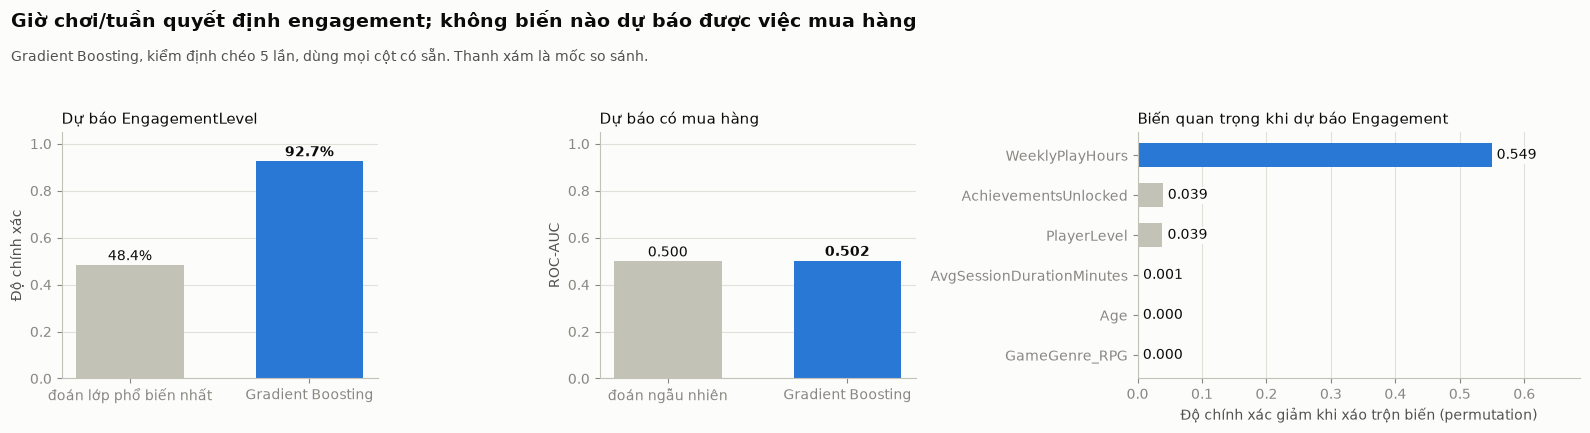

In [26]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.inspection import permutation_importance

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
X_all = pd.get_dummies(df.drop(columns=['PlayerID', 'EngagementLevel', 'InGamePurchases', 'Cluster', 'Segment', 'GMM_MaxProb']), dtype=float)
hgb = HistGradientBoostingClassifier(random_state=SEED)

eng_acc = cross_val_score(hgb, X_all, df['EngagementLevel'], cv=cv, scoring='accuracy')
eng_base = df['EngagementLevel'].value_counts(normalize=True).max()
buy_auc = cross_val_score(hgb, X_all.assign(Engagement=eng_code), df['InGamePurchases'], cv=cv, scoring='roc_auc')
print(f'Engagement: accuracy = {eng_acc.mean():.3f} ± {eng_acc.std():.3f} (majority baseline {eng_base:.3f})')
print(f'Purchase:   ROC-AUC  = {buy_auc.mean():.3f} ± {buy_auc.std():.3f} (random = 0.500)')

Xa, Xb, ya, yb = train_test_split(X_all, df['EngagementLevel'], test_size=0.2, stratify=df['EngagementLevel'], random_state=SEED)
pi = permutation_importance(hgb.fit(Xa, ya), Xb, yb, n_repeats=5, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=Xb.columns).sort_values(ascending=False).head(6)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={'width_ratios': [1, 1, 1.4]})
for a, (val, base, title, fmt, base_lbl) in zip(axes[:2], [
        (eng_acc.mean(), eng_base, 'Dự báo EngagementLevel', '{:.1%}', 'đoán lớp phổ biến nhất'),
        (buy_auc.mean(), 0.5, 'Dự báo có mua hàng', '{:.3f}', 'đoán ngẫu nhiên')]):
    a.bar([0, 1], [base, val], color=[GRAY, BLUE], width=0.6)
    for x, v in zip([0, 1], [base, val]):
        a.text(x, v + 0.02, fmt.format(v), ha='center', color=INK, fontweight='bold' if x else 'normal')
    a.set_xticks([0, 1], [base_lbl, 'Gradient Boosting']); a.set_ylim(0, 1.05); a.grid(axis='x', visible=False)
    a.set_title(title)
axes[0].set_ylabel('Độ chính xác'); axes[1].set_ylabel('ROC-AUC')
a = axes[2]
yy = np.arange(len(imp))[::-1]
a.barh(yy, imp, color=[BLUE] + [GRAY] * (len(imp) - 1), height=0.6)
label_bars(a, imp, yy, '{:.3f}', pad=0.008)
a.set_yticks(yy, imp.index); a.set_xlim(0, imp.max() * 1.25); a.grid(axis='y', visible=False)
a.set_title('Biến quan trọng khi dự báo Engagement'); a.set_xlabel('Độ chính xác giảm khi xáo trộn biến (permutation)')
finish(fig, '19_supervised_checks', 'Giờ chơi/tuần quyết định engagement; không biến nào dự báo được việc mua hàng',
       'Gradient Boosting, kiểm định chéo 5 lần, dùng mọi cột có sẵn. Thanh xám là mốc so sánh.')

**Kết luận:**
1. **Engagement:** Gradient Boosting đạt độ chính xác ≈ **93%** (đoán bừa lớp phổ biến nhất chỉ đạt 48%). Permutation importance cho thấy **giờ chơi/tuần áp đảo** mọi biến khác: xáo trộn biến này làm độ chính xác giảm khoảng 55 điểm phần trăm, các biến còn lại gần như không đáng kể. Phát hiện ở mục 2.1 được xác nhận.
2. **Mua hàng:** ROC-AUC ≈ **0,50**, đúng bằng đoán ngẫu nhiên, dù dùng mọi cột kể cả engagement. Trong dataset này, **không có thông tin nào dự báo được việc ai sẽ mua hàng**. Kết luận "không có nhóm High-Spender" ở mục 10 được xác nhận bằng một mô hình mạnh, không chỉ bằng kiểm định χ².

## 12. Chiến lược monetization

Nguyên tắc: mỗi nhóm có **động lực chơi** khác nhau, sản phẩm bán ra phải đánh đúng động lực đó. **Mức độ tin cậy** lấy từ phân tích độ ổn định ở mục 8.

| Phân khúc | Động lực | Mục tiêu | Chiến lược cụ thể | Độ tin cậy |
|---|---|---|---|---|
| **Hardcore** (19%) | Thời gian, sự gắn bó | Tối đa giá trị vòng đời (LTV), giữ chân | **Season / battle pass** (thưởng theo thời gian chơi); **subscription** hằng tháng; cosmetic cao cấp thể hiện vị thế; nội dung end-game trả phí. Không giảm giá sâu vì nhóm đã gắn bó. | **Cao**: nhóm được tìm lại ở mọi lần chạy |
| **Veteran Grinders** (26%) | Tiến trình dài hạn | Ngăn rời bỏ khi hết nội dung | **DLC / bản mở rộng**, chế độ mới; **vật phẩm uy tín** chỉ dành cho level cao; sự kiện giới hạn thời gian. | Trung bình |
| **Achievement Hunters** (25%) | Hoàn thành, sưu tập | Biến động lực sưu tập thành doanh thu | **Bộ sưu tập** có thưởng hoàn thành; loot box có **pity minh bạch**; **XP booster** đánh vào điểm yếu level thấp. | Trung bình |
| **Casual** (30%) | Giải trí nhẹ nhàng | Chuyển đổi lần mua đầu | **Starter pack** giá rẻ; **rewarded ads**; ưu đãi lần mua đầu; thưởng **đăng nhập hằng ngày** để tăng giờ chơi, dần đưa họ lên nhóm gắn bó hơn. | Trung bình |

**Áp dụng chung:**
- **Gắn phân khúc cho người chơi mới** bằng các quy tắc cây quyết định ở mục 11.2 (≈ 91% chính xác), không cần chạy lại phân cụm.
- Vì ba nhóm không phải Hardcore có ranh giới mềm (mục 8, mục 11.1: 21–30% người chơi giáp ranh), nên **cá nhân hóa theo hai trục liên tục** *level* và *thành tựu* của từng người thay vì gán cứng vào nhóm.
- ~20% người đã từng mua trong mỗi nhóm là khách hàng ưu tiên cho ưu đãi cá nhân hóa.
- Triển khai bằng **A/B test**, đo tỉ lệ chuyển đổi và doanh thu trung bình trên mỗi người chơi (ARPU) trước khi áp dụng rộng.
- **Đòn bẩy lớn nhất:** engagement được quyết định bởi giờ chơi/tuần (mục 2.1), nên mọi tính năng tăng số phiên hoặc độ dài phiên (sự kiện hằng ngày, nhiệm vụ tuần) sẽ đẩy người chơi lên nhóm Hardcore, nhóm có giá trị cao nhất.

## 13. Kết luận và hạn chế

### Kết luận
1. **Đặc trưng:** giờ chơi/tuần, level và thành tựu là bộ đầu vào tốt nhất (ablation), độc lập với nhau. `PlayTimeHours` là nhiễu; `EngagementLevel` gần như được suy ra từ giờ chơi/tuần.
2. **Xu hướng cụm yếu:** Hopkins ≈ 0,58, nên Silhouette vừa phải là giới hạn của dữ liệu.
3. **Phương pháp:** Ward và Complete cho cụm cân đối; Ward được chọn vì cùng hàm mục tiêu với K-Means. Hybrid Agglomerative → K-Means đạt Silhouette ≈ 0,28, Davies-Bouldin ≈ 1,06: tốt hơn rõ Agglomerative đơn thuần, ngang K-Means++, với một lần chạy và tâm khởi tạo giải thích được.
4. **Phân khúc:** 4 nhóm (Hardcore, Veteran Grinders, Achievement Hunters, Casual), khác nhau thuần túy ở hành vi; giống nhau về tuổi, khu vực, độ khó.
5. **Độ ổn định:** **Hardcore** là phân khúc vững nhất (tìm lại ở mọi lần chạy, trùng ≈ 85%); ba nhóm còn lại là cách chia một vùng phân bố đều theo level × thành tựu. Sự bất ổn này đến từ dữ liệu, nên cả Hybrid lẫn K-Means đều chịu ảnh hưởng như nhau.
6. **Chi tiêu:** không có khác biệt giữa các nhóm (χ², p ≈ 0,36); Gradient Boosting dùng mọi cột chỉ đạt AUC ≈ 0,50. Không có nhóm High-Spender, và không biến nào dự báo được việc mua hàng.
7. **Mô hình bổ sung:** GMM xác nhận độc lập kết quả độ ổn định (Hardcore ≈ 1% giáp ranh, ba nhóm kia 21–30%). Cây quyết định 3 tầng cho bộ quy tắc gán phân khúc chính xác ≈ 91%. Gradient Boosting xác nhận giờ chơi/tuần quyết định engagement (độ chính xác ≈ 93%).

### Hạn chế
- Không có **win/loss ratio**; skill score và item collection rate dùng proxy.
- `InGamePurchases` nhị phân, không đo được mức chi tiêu.
- Dữ liệu tổng hợp (Hopkins gần ngẫu nhiên), nên các kết luận cần kiểm chứng trên dữ liệu thật.

### Hướng phát triển
- Bổ sung dữ liệu giao dịch (số tiền, tần suất mua) để xác định High-Spenders và ước tính doanh thu từng nhóm.
- Theo dõi người chơi theo thời gian (dữ liệu nhiều thời điểm) để đo **chuyển dịch giữa các phân khúc**, ví dụ bao nhiêu người Casual trở thành Hardcore sau một sự kiện.
- Kiểm chứng các quy tắc cây quyết định bằng A/B test trên người chơi thật.

In [27]:
profile.round(3).to_csv(f'{FIG_DIR}/segment_profile.csv')
eval_df.round(4).to_csv(f'{FIG_DIR}/evaluation.csv')
ablation.round(4).to_csv(f'{FIG_DIR}/feature_ablation.csv')
stab.round(4).to_csv(f'{FIG_DIR}/stability.csv', index=False)
depth_df.round(4).to_csv(f'{FIG_DIR}/segment_tree_depth.csv')
print('Saved to', FIG_DIR)

Saved to ../reports/figures
